# Empirical Exploration of ATAS with Qwen/Qwen2.5-0.5B-Instruct

This project focuses on testing and validating the empirical foundations of ATAS. In particular, it assesses whether model activations can be used to infer information about the task even when the task is not explicitly stated in the prompt.

## Requirements

- **pysteer** library


# Variables

In [1]:
import os
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["CUDA_VISIBLE_DEVICES"] = "0"  # nvidia-smi GPU 0 with PCI ordering.
TARGET_GPU_NAME = "Quadro RTX 8000"
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

PYSTEER_ROOT = "pysteer/"
MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"
MODEL_REVISION = "7ae557604adf67be50417f59c2c2f167def9a775"
HF_TOKEN = ""

BATCH_SIZE = 16
# Match the generation input cap across Llama, OLMo and Qwen.
MAX_LEN = 1024
LAYER_MODE = "config"
RANDOM_SEED = 42
LAYERS_TO_EXTRACT = [11, 12, 13]

print("Config ready.")

Config ready.


In [2]:
import os
import random
import site
import subprocess
import sys
from importlib.metadata import PackageNotFoundError, version

packages = {
    "numpy": "1.26.4",
    "scipy": "1.13.1",
    "scikit-learn": "1.4.2",
    "pandas": "2.2.2",
    "matplotlib": "3.8.4",
    "numexpr": "2.10.2",
    "joblib": "1.3.2",
    "threadpoolctl": "3.1.0",
    "numba": "0.60.0",
    "pynndescent": None,
    "tqdm": None,
    "openTSNE": None,
    "torch": None,
    "transformers": None,
    "huggingface_hub": None,
    "accelerate": None,
    "ipywidgets": None,
}

def needs_install(pkg_name: str, wanted: str | None) -> bool:
    try:
        current = version(pkg_name)
    except PackageNotFoundError:
        return True
    if wanted is None:
        return False
    return current != wanted

to_install = []
for pkg, wanted in packages.items():
    if needs_install(pkg, wanted):
        to_install.append(f"{pkg}=={wanted}" if wanted else pkg)

if to_install:
    cmd = [
        sys.executable, "-m", "pip", "install",
        "--no-cache-dir", "--upgrade",
        *to_install
    ]
    print("RUN:", " ".join(cmd))
    subprocess.check_call(cmd)
else:
    print("Dependencies already aligned. No installation required.")

Dependencies already aligned. No installation required.


In [3]:
import gc
import hashlib
import json
import logging
import math
import os
import re
import site
import sys
from dataclasses import dataclass
from functools import lru_cache
from itertools import islice
from pathlib import Path
from typing import Any, Callable, Dict, Iterable, List, Mapping, Optional, Tuple

USER_SITE = site.getusersitepackages()
if USER_SITE not in sys.path:
    sys.path.insert(0, USER_SITE)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
import torch

from IPython.display import display
from datasets import Audio, load_dataset
from matplotlib.axes import Axes
from matplotlib.figure import Figure
from matplotlib.patches import Ellipse
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
from openTSNE import TSNE
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler, normalize
from transformers import AutoModelForCausalLM, AutoTokenizer

if HF_TOKEN:
    from huggingface_hub import login
    login(token=HF_TOKEN)
    print("Login OK.")
else:
    print("HF_TOKEN not set: if the model/dataset is gated, log in manually.")

def resolve_pysteer_path(path: Optional[str]) -> str:
    if path and os.path.isdir(path):
        return path

    candidates = []
    base = "/"
    if os.path.isdir(base):
        for d in os.listdir(base):
            p = os.path.join(base, d, "pysteer")
            if os.path.isdir(p):
                candidates.append(p)

    if candidates:
        found = candidates[0]
        print("PYSTEER_PATH auto-detected:", found)
        return found

    raise FileNotFoundError(
        f"Can't find pysteer at: {path}\n"
        "Update PYSTEER_PATH to your path (or set the PYSTEER_PATH env var)."
    )

PYSTEER_PATH = resolve_pysteer_path(PYSTEER_ROOT)

if PYSTEER_PATH not in sys.path:
    sys.path.insert(0, PYSTEER_PATH)

from activation_manager.ActivationExtractor import ActivationExtractor
from executor import Executor
from enums.ApplyFromModeEnum import ApplyFromModeEnum
from enums.MediatorTypeEnum import MediatorTypeEnum
from enums.ModelTypeEnum import ModelTypeEnum
from enums.TaskTypeEnum import TaskTypeEnum
from prompt_generator.Qwen2Point5PromptGenerator import Qwen2Point5PromptGenerator
from steering_strategy.AtasSteeringStrategy import AtasSteeringStrategy
from utils.ModelUtils import ModelUtils
from vector_update_strategy.AtasVectorMediator import AtasVectorMediator

HF_TOKEN not set: if the model/dataset is gated, log in manually.


# Model

In [4]:
import os
import site
import sys

USER_SITE = site.getusersitepackages()
if USER_SITE not in sys.path:
    sys.path.insert(0, USER_SITE)

PYSTEER_PATH = PYSTEER_ROOT if os.path.isdir(PYSTEER_ROOT) else None
if PYSTEER_PATH and PYSTEER_PATH not in sys.path:
    sys.path.insert(0, PYSTEER_PATH)

import torch
from huggingface_hub import login
from transformers import AutoModelForCausalLM, AutoTokenizer

from utils.ModelUtils import ModelUtils

if HF_TOKEN:
    login(token=HF_TOKEN)
    print("Login OK.")
else:
    print("HF_TOKEN not set: if the model/dataset is gated, log in manually.")

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, revision=MODEL_REVISION, use_fast=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "left"

if hasattr(tokenizer, "truncation_side"):
    tokenizer.truncation_side = "left"

if not torch.cuda.is_available():
    raise RuntimeError("A CUDA-capable GPU is required to run this notebook.")

active_gpu_name = torch.cuda.get_device_name()
if active_gpu_name != TARGET_GPU_NAME:
    raise RuntimeError(
        f"Expected {TARGET_GPU_NAME!r}, but CUDA exposed {active_gpu_name!r}. "
        "Restart the kernel and run the notebook from the first cell."
    )

major, minor = torch.cuda.get_device_capability()
dtype = torch.bfloat16 if major >= 8 and torch.cuda.is_bf16_supported() else torch.float16

# Fast SDPA on supported GPUs; RTX 8000 uses memory-efficient SDPA with math fallback.
flash_sdp_supported = major >= 8
torch.backends.cuda.enable_flash_sdp(flash_sdp_supported)
torch.backends.cuda.enable_mem_efficient_sdp(True)
torch.backends.cuda.enable_math_sdp(True)
print(f"GPU: {active_gpu_name} | capability={major}.{minor} | flash_sdp={flash_sdp_supported}")

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    revision=MODEL_REVISION,
    torch_dtype=dtype,
    device_map="auto",
    attn_implementation="sdpa",
)

model.eval()
model_dtype = getattr(model, "dtype", torch.float32)

all_layers = ModelUtils.find_transformer_layers(model)
NUM_LAYERS = len(all_layers)

if LAYER_MODE == "middle":
    mid = int(math.ceil((NUM_LAYERS - 1) / 2))
    LAYERS_TO_EXTRACT = [mid]
elif LAYER_MODE == "config":
    if "LAYERS_TO_EXTRACT" not in globals():
        raise ValueError("LAYER_MODE='config' requires LAYERS_TO_EXTRACT to be defined in the configuration cell.")
    LAYERS_TO_EXTRACT = sorted({int(x) for x in LAYERS_TO_EXTRACT})

else:
    raise ValueError(
        f"Invalid LAYER_MODE: {LAYER_MODE!r}. Allowed values: 'middle', 'config'."
    )

if not LAYERS_TO_EXTRACT:
    raise ValueError("LAYERS_TO_EXTRACT cannot be empty.")

if any((L < 0 or L >= NUM_LAYERS) for L in LAYERS_TO_EXTRACT):
    raise ValueError(
        f"LAYERS_TO_EXTRACT out of range [0, {NUM_LAYERS - 1}]: {LAYERS_TO_EXTRACT}"
    )

print(f"Total transformer layers: {NUM_LAYERS}")
print(f"Layers used for steering: {LAYERS_TO_EXTRACT}")

HF_TOKEN not set: if the model/dataset is gated, log in manually.


`torch_dtype` is deprecated! Use `dtype` instead!


GPU: Quadro RTX 8000 | capability=7.5 | flash_sdp=False


Total transformer layers: 24
Layers used for steering: [11, 12, 13]


# Datasets

In [5]:
prompt_generator = Qwen2Point5PromptGenerator(ModelTypeEnum.INSTRUCT)


def build_qwen25_prompt(system: str, user: str, who_you_are: str = "") -> str:
    return prompt_generator.generate_prompt(
        system=system,
        user=user,
        who_you_are=who_you_are,
    )


TASK_CLUSTER_COLORS = [
    "#6F5FA7", "#B08A2E", "#99C0D7", "#356587", "#5B8C3B", "#2F7E7A"
]


def _task_color_map(task_ids: dict) -> dict:
    if not task_ids:
        return {}
    max_tid = max(task_ids.values())
    if max_tid >= len(TASK_CLUSTER_COLORS):
        raise ValueError(f"Not enough colors: need {max_tid + 1}, have {len(TASK_CLUSTER_COLORS)}")
    return {name: TASK_CLUSTER_COLORS[tid] for name, tid in task_ids.items()}

# Activation extraction

In [6]:
def get_last_nonpad_positions(attention_mask: torch.Tensor) -> torch.Tensor:
    rev = attention_mask.flip(dims=[1])
    has_any = rev.any(dim=1)
    last_from_end = rev.long().argmax(dim=1)
    last_pos = attention_mask.size(1) - 1 - last_from_end
    return torch.where(has_any, last_pos, torch.zeros_like(last_pos)).long()


def _masked_prompt_representations(
        acts: torch.Tensor,
        attention_mask: torch.Tensor,
        *,
        use_last_token_for_prompt: bool = True,
) -> torch.Tensor:
    acts = acts.to(torch.float32)

    if bool(use_last_token_for_prompt):
        last_pos = get_last_nonpad_positions(attention_mask).to(device=acts.device, dtype=torch.long)
        b_idx = torch.arange(acts.size(0), dtype=torch.long, device=acts.device)
        return acts[b_idx, last_pos, :]

    mask = attention_mask.to(device=acts.device, dtype=acts.dtype).unsqueeze(-1)
    den = mask.sum(dim=1).clamp_min(1.0)
    return (acts * mask).sum(dim=1) / den


@torch.inference_mode()
def extract_prompt_last_token_vectors(
        model,
        tokenizer,
        prompts: List[str],
        layers_to_extract: List[int],
        batch_size: int = 16,
        max_len: int = None,
        gc_every: int = 50,
        empty_cache_every: int = 0,
        decode_chunk_max: int = 1,
        use_last_token_for_prompt: bool = True,
) -> Tuple[np.ndarray, List[int]]:
    if not prompts:
        return np.zeros((0, 0), dtype=np.float32), []

    gc_every = max(50, int(gc_every)) if gc_every else 0
    used_layers = sorted(set(int(x) for x in layers_to_extract))
    if not used_layers:
        raise ValueError("layers_to_extract must contain at least one layer.")

    base = ModelUtils.unwrap_model(model)
    device = Executor._infer_input_device(model)

    extractor = ActivationExtractor(
        model=model,
        layers_to_extract=used_layers,
        offload_to_cpu=True,
        decode_chunk_max=int(decode_chunk_max),
    )

    if max_len is None:
        cfg = getattr(base, "config", None)
        cfg_max = int(getattr(cfg, "max_position_embeddings", 0) or 0) if cfg is not None else 0
        tok_max = getattr(tokenizer, "model_max_length", None)
        tok_max_int = 0
        try:
            if tok_max is not None:
                tok_max_int = int(tok_max)
                if tok_max_int >= 10 ** 9:
                    tok_max_int = 0
        except Exception:
            tok_max_int = 0
        fallback = MAX_LEN if isinstance(MAX_LEN, int) and MAX_LEN > 0 else 1024
        candidates = [x for x in (cfg_max, tok_max_int) if isinstance(x, int) and x > 0]
        max_len = min(candidates) if candidates else fallback

    original_prompts = list(prompts)
    length_enc = tokenizer(
        original_prompts,
        padding=False,
        truncation=True,
        max_length=int(max_len),
        add_special_tokens=False,
    )
    prompt_lengths = [len(ids) for ids in length_enc["input_ids"]]
    sort_order = sorted(range(len(original_prompts)), key=lambda idx: prompt_lengths[idx])
    prompts = [original_prompts[idx] for idx in sort_order]
    del length_enc, prompt_lengths

    X_parts = []
    with extractor:
        i = 0
        bi = 0
        current_batch_size = max(1, int(batch_size))
        while i < len(prompts):
            batch = prompts[i:i + current_batch_size]

            enc = tokenizer(
                batch,
                return_tensors="pt",
                padding=True,
                truncation=True,
                max_length=max_len,
                add_special_tokens=False,
            )
            enc = {k: v.to(device) for k, v in enc.items()}
            att = enc["attention_mask"]

            extractor.clear()
            try:
                model(**enc, use_cache=False)
            except RuntimeError as exc:
                if "out of memory" not in str(exc).lower():
                    raise
                extractor.clear()
                del enc, att
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()
                if len(batch) <= 1:
                    raise
                current_batch_size = max(1, len(batch) // 2)
                print(f"[clustering] CUDA OOM at batch={len(batch)}; retrying with batch={current_batch_size}.")
                continue
            extractor.assert_ok()

            acts_full = dict(extractor.finalize(clear_chunks=True).items())
            att_cpu = att.detach().to("cpu", dtype=torch.bool)

            vecs_this = []
            for L in used_layers:
                acts = acts_full.get(L, None)
                if acts is None:
                    got = sorted(acts_full.keys())
                    raise RuntimeError(f"No activations captured for layer {L}. Got={got}")

                v = _masked_prompt_representations(
                    acts=acts,
                    attention_mask=att_cpu,
                    use_last_token_for_prompt=bool(use_last_token_for_prompt),
                )
                vecs_this.append(v.to(torch.float32).cpu().numpy())

            X_parts.append(np.concatenate(vecs_this, axis=1))

            extractor.clear()
            del enc, att, att_cpu, acts_full, vecs_this
            if torch.cuda.is_available() and empty_cache_every and ((bi + 1) % empty_cache_every == 0):
                torch.cuda.empty_cache()
            if gc_every and ((bi + 1) % gc_every == 0):
                gc.collect()
            i += len(batch)
            bi += 1

    X_sorted = np.concatenate(X_parts, axis=0)
    X = np.empty_like(X_sorted)
    X[np.asarray(sort_order, dtype=np.int64)] = X_sorted
    return X, used_layers

# Training prompts for clustering / prototypes

In [7]:
def _pick_writable_base():
    candidates = [
        os.environ.get("SCRATCH"),
        os.environ.get("LOCAL_SCRATCH"),
        os.environ.get("TMPDIR"),
        f"/scratch/{os.environ.get('USER', '')}",
        f"/tmp/{os.environ.get('USER', '')}",
        str(Path.home() / ".cache"),
    ]
    for base in candidates:
        if not base:
            continue
        try:
            os.makedirs(base, exist_ok=True)
            test = os.path.join(base, ".write_test")
            with open(test, "w", encoding="utf-8") as f:
                f.write("ok")
            os.remove(test)
            return base
        except Exception:
            pass
    raise RuntimeError("No writable directory found for caches.")


CACHE_BASE = _pick_writable_base()
HF_ROOT = os.path.join(CACHE_BASE, "hf_cache")
LIBRITTS_ROOT = os.path.join(CACHE_BASE, "libritts_r_slim_2cols")

for p in [HF_ROOT, os.path.join(HF_ROOT, "hub"), os.path.join(HF_ROOT, "datasets"), os.path.join(HF_ROOT, "xet"),
          LIBRITTS_ROOT]:
    os.makedirs(p, exist_ok=True)

os.environ["HF_HOME"] = HF_ROOT
os.environ["HF_HUB_CACHE"] = os.path.join(HF_ROOT, "hub")
os.environ["HUGGINGFACE_HUB_CACHE"] = os.path.join(HF_ROOT, "hub")
os.environ["HF_DATASETS_CACHE"] = os.path.join(HF_ROOT, "datasets")
os.environ["HF_XET_CACHE"] = os.path.join(HF_ROOT, "xet")
os.environ["HF_HUB_DISABLE_XET"] = "1"
os.environ["LIBRITTS_SLIM_CACHE_DIR"] = LIBRITTS_ROOT

print("CACHE_BASE =", CACHE_BASE)
print("HF_DATASETS_CACHE =", os.environ["HF_DATASETS_CACHE"])
print("LIBRITTS_SLIM_CACHE_DIR =", os.environ["LIBRITTS_SLIM_CACHE_DIR"])

CACHE_BASE = /tmp/ubuntu
HF_DATASETS_CACHE = /tmp/ubuntu/hf_cache/datasets
LIBRITTS_SLIM_CACHE_DIR = /tmp/ubuntu/libritts_r_slim_2cols


In [8]:
def prepare_shared_task_data() -> Dict[str, Dict[str, object]]:
    from datasets import Dataset, DatasetDict

    task_data_by_name: Dict[str, Dict[str, object]] = {}
    task_names = list(ACTIVE_TASK_IDS.keys())

    for task_name in task_names:
        print(f"[DATA] build merged pool -> {task_name}")

        if task_name == "libritts_text_original_to_normalized":
            task_data = _prepare_libritts_shared_task_data()
            train_df = task_data["df_train"]
            val_df = task_data["df_val"]
            test_df = task_data["df_test"]
            merged_df = task_data["df_merged"]
            available_splits = task_data["available_original_splits"]
        else:
            merged_df, available_splits = _merge_available_binary_splits(task_name)
            train_df, val_df, test_df = _split_binary_pool_random(
                merged_df,
                val_count=CLASSIFIER_VAL_COUNT,
                test_frac=CLASSIFIER_TEST_FRACTION,
            )
            task_data = {
                "df_train": train_df,
                "df_val": val_df,
                "df_test": test_df,
                "df_merged": merged_df,
                "available_original_splits": available_splits,
            }

        train_hf = Dataset.from_pandas(train_df[["text", "label"]].reset_index(drop=True), preserve_index=False)
        val_hf = Dataset.from_pandas(val_df[["text", "label"]].reset_index(drop=True), preserve_index=False)
        test_hf = Dataset.from_pandas(test_df[["text", "label"]].reset_index(drop=True), preserve_index=False)
        task_data["hf"] = DatasetDict(train=train_hf, validation=val_hf, test=test_hf)
        task_data_by_name[task_name] = task_data

        if task_name == "libritts_text_original_to_normalized":
            print(
                f"[DATA] {task_name}: paired merged={len(task_data['df_paired_merged'])} from {available_splits} | "
                f"paired train={len(task_data['df_paired_train'])} | "
                f"paired validation={len(task_data['df_paired_val'])} | "
                f"paired test={len(task_data['df_paired_test'])}"
            )
        else:
            print(
                f"[DATA] {task_name}: merged={len(merged_df)} from {available_splits} | "
                f"train={len(train_df)} (label0={int((train_df.label == 0).sum())}, label1={int((train_df.label == 1).sum())}) | "
                f"validation={len(val_df)} (label0={int((val_df.label == 0).sum())}, label1={int((val_df.label == 1).sum())}) | "
                f"test={len(test_df)} (label0={int((test_df.label == 0).sum())}, label1={int((test_df.label == 1).sum())})"
            )

    return task_data_by_name


TASK_IDS = {
    "libritts_text_original_to_normalized": 0,
    "paradetox_non_toxic": 1,
    "imdb_positive_sentiment": 2,
    "stanford_politeness_polite": 3,
    "authormix_woolf_style": 4,
    "setfit_subj_objective": 5,
}

TASK_COLORS = _task_color_map(TASK_IDS)

TASK_DATASET_SOURCES = {
    "libritts_text_original_to_normalized": "mythicinfinity/libritts_r",
    "paradetox_non_toxic": "s-nlp/en_paradetox_toxicity",
    "imdb_positive_sentiment": "imdb",
    "stanford_politeness_polite": "Cleanlab/stanford-politeness",
    "authormix_woolf_style": "hallisky/AuthorMix",
    "setfit_subj_objective": "SetFit/subj",
}

SEED = int(globals().get("RANDOM_SEED", 42) or 42)
RANDOM_SEED = SEED
STEERING_TRAIN_PER_CLASS = 50
PROMPT_VARIANT_COUNT = 100
PROMPT_SPLIT_FRACTIONS = {
    "train": 0.70,
    "validation": 0.10,
    "test": 0.20,
}

REWRITE_TARGET_LABEL = 1
LIBRITTS_SOURCE_SPLITS = {
    "train": ["train.clean.100", "train.clean.360", "train.other.500"],
    "validation": ["dev.clean", "dev.other"],
    "test": ["test.clean", "test.other"],
}
LIBRITTS_SLIM_CACHE_VERSION = 1


def _default_libritts_slim_cache_dir() -> str:
    explicit = (
        globals().get("LIBRITTS_SLIM_CACHE_DIR")
        or os.environ.get("LIBRITTS_SLIM_CACHE_DIR")
        or os.environ.get("PYSTEER_LIBRITTS_SLIM_CACHE_DIR")
    )
    if explicit:
        return os.path.abspath(os.path.expanduser(str(explicit)))

    candidates = []

    for env_name in ("SCRATCH", "LOCAL_SCRATCH", "TMPDIR"):
        val = os.environ.get(env_name)
        if val:
            candidates.append(os.path.abspath(os.path.expanduser(val)))

    user_name = os.environ.get("USER") or os.path.basename(os.path.expanduser("~"))
    candidates.extend([
        f"/scratch/{user_name}",
        f"/tmp/{user_name}",
        os.path.expanduser("~/.cache/pysteer"),
    ])

    for base in candidates:
        try:
            os.makedirs(base, exist_ok=True)
            probe = os.path.join(base, ".pysteer_write_test")
            with open(probe, "w", encoding="utf-8") as f:
                f.write("ok")
            os.remove(probe)
            return os.path.join(base, "libritts_r_slim_2cols")
        except Exception:
            continue

    return os.path.expanduser("~/libritts_r_slim_2cols")


LIBRITTS_SLIM_CACHE_DIR = _default_libritts_slim_cache_dir()
LIBRITTS_DATASET_NAME = "mythicinfinity/libritts_r"
IMDB_DATASET_NAME = "stanfordnlp/imdb"
STANFORD_POLITENESS_DATASET_NAME = "Cleanlab/stanford-politeness"
PARADETOX_TOXICITY_DATASET_NAME = "s-nlp/en_paradetox_toxicity"
AUTHORMIX_DATASET_NAME = "hallisky/AuthorMix"
SETFIT_SUBJ_DATASET_NAME = "SetFit/subj"
ALPACA_DATASET_NAME = "tatsu-lab/alpaca"

ORIGINAL_SPLIT_ORDER = ("train", "validation", "test")
CLASSIFIER_VAL_COUNT = 400
CLASSIFIER_TEST_FRACTION = 0.20
PAIRED_EVAL_TASKS = {"libritts_text_original_to_normalized"}

ACTIVE_TASK_IDS = dict(TASK_IDS)
SKIPPED_TASK_IDS = {}


def _truncate(s: str, max_chars: int = 4000) -> str:
    s = "" if s is None else str(s)
    s = " ".join(s.split())
    return s[:max_chars]


def _first_present(d: dict, keys: List[str]) -> Optional[str]:
    for k in keys:
        if k in d and d[k] is not None:
            return k
    return None


def _shuffle_df(df: pd.DataFrame) -> pd.DataFrame:
    if df.empty:
        return df.copy().reset_index(drop=True)
    return df.sample(frac=1.0, random_state=SEED).reset_index(drop=True)


def _empty_binary_text_df() -> pd.DataFrame:
    return pd.DataFrame(columns=["text", "label"])


def _empty_paired_rewrite_df() -> pd.DataFrame:
    return pd.DataFrame(
        columns=["raw_text", "target_text", "dataset", "task_id", "gold_label", "target_label", "reference"]
    )


def _empty_prompt_only_df() -> pd.DataFrame:
    return pd.DataFrame(columns=["raw_text"])


def _prepare_binary_df(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df["text"] = df["text"].astype(str).map(_truncate)
    df["label"] = df["label"].astype(int)
    df = df[df["text"].str.len() > 0].reset_index(drop=True)
    df = df.drop_duplicates(subset=["text", "label"]).reset_index(drop=True)

    parts = []
    for lab in (0, 1):
        part = df[df["label"] == lab].copy()
        if not part.empty:
            parts.append(part)

    if not parts:
        return _empty_binary_text_df()

    out = pd.concat(parts, ignore_index=True)
    return _shuffle_df(out)


def _prepare_prompt_only_df(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()

    source_col = "raw_text" if "raw_text" in df.columns else "text"
    if source_col not in df.columns:
        return _empty_prompt_only_df()

    df["raw_text"] = df[source_col].astype(str).map(_truncate)
    df = df[df["raw_text"].str.len() > 0].reset_index(drop=True)
    df = df.drop_duplicates(subset=["raw_text"]).reset_index(drop=True)

    if df.empty:
        return _empty_prompt_only_df()

    return _shuffle_df(df[["raw_text"]])


def _stream_binary_df(
    ds,
    emit: Callable[[dict], Iterable[Tuple[str, Optional[int]]]],
) -> pd.DataFrame:
    rows: List[dict] = []

    for ex in ds:
        for text, lab in emit(ex):
            if lab is None:
                continue
            lab = int(lab)
            if lab not in (0, 1):
                continue

            text = _truncate(text)
            if not text:
                continue

            rows.append({"text": text, "label": lab})

    if not rows:
        return _empty_binary_text_df()

    return _prepare_binary_df(pd.DataFrame(rows))


def _iter_dataset_streams(streams):
    for stream in streams:
        for ex in stream:
            yield ex


def _compute_split_counts(
    total_count: int,
    *,
    val_count: int = CLASSIFIER_VAL_COUNT,
    test_frac: float = CLASSIFIER_TEST_FRACTION,
) -> Tuple[int, int, int]:
    total_count = int(total_count)
    val_count = int(val_count)

    if total_count <= 0:
        return 0, 0, 0

    if val_count < 0:
        raise ValueError("val_count must be >= 0")
    if not (0.0 <= float(test_frac) < 1.0):
        raise ValueError("test_frac must be in [0, 1)")

    n_val = min(val_count, total_count)

    n_test = int(math.floor(total_count * float(test_frac)))

    max_test_allowed = max(0, total_count - n_val)
    n_test = min(n_test, max_test_allowed)

    n_train = total_count - n_val - n_test

    if n_train < 0:
        raise ValueError("Invalid split sizes: train became negative.")

    return n_train, n_val, n_test


def _split_binary_pool_random(
    df: pd.DataFrame,
    *,
    val_count: int = CLASSIFIER_VAL_COUNT,
    test_frac: float = CLASSIFIER_TEST_FRACTION,
) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    df = _prepare_binary_df(df)
    if df.empty:
        empty = _empty_binary_text_df()
        return empty, empty, empty

    df = _shuffle_df(df)
    n_train, n_val, n_test = _compute_split_counts(
        len(df),
        val_count=val_count,
        test_frac=test_frac,
    )

    train_df = df.iloc[:n_train].reset_index(drop=True)
    val_df = df.iloc[n_train:n_train + n_val].reset_index(drop=True)
    test_df = df.iloc[n_train + n_val:n_train + n_val + n_test].reset_index(drop=True)

    for split_name, split_df in (("train", train_df), ("validation", val_df), ("test", test_df)):
        labels = set(split_df["label"].astype(int).unique().tolist())
        if labels != {0, 1}:
            raise RuntimeError(
                f"Invalid random split for binary task: {split_name} must contain both classes 0 and 1, "
                f"found {sorted(labels)}."
            )

    return train_df, val_df, test_df


def _split_paired_pool(
    pair_df: pd.DataFrame,
    *,
    val_count: int = CLASSIFIER_VAL_COUNT,
    test_frac: float = CLASSIFIER_TEST_FRACTION,
) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    pair_df = pair_df.copy().reset_index(drop=True)
    if pair_df.empty:
        empty = _empty_paired_rewrite_df()
        return empty, empty, empty

    pair_df = _shuffle_df(pair_df)
    n_train, n_val, n_test = _compute_split_counts(
        len(pair_df),
        val_count=val_count,
        test_frac=test_frac,
    )

    train_df = pair_df.iloc[:n_train].reset_index(drop=True)
    val_df = pair_df.iloc[n_train:n_train + n_val].reset_index(drop=True)
    test_df = pair_df.iloc[n_train + n_val:n_train + n_val + n_test].reset_index(drop=True)
    return train_df, val_df, test_df


def _expand_paired_split_to_binary_df(pair_df: pd.DataFrame) -> pd.DataFrame:
    if pair_df is None or pair_df.empty:
        return _empty_binary_text_df()

    part0 = pd.DataFrame({
        "text": pair_df["raw_text"].astype(str),
        "label": np.zeros(len(pair_df), dtype=int),
    })
    part1 = pd.DataFrame({
        "text": pair_df["target_text"].astype(str),
        "label": np.ones(len(pair_df), dtype=int),
    })

    return _prepare_binary_df(pd.concat([part0, part1], ignore_index=True))


@lru_cache(maxsize=8)
def _build_imdb_df(split_name: str) -> pd.DataFrame:
    ds = load_dataset(IMDB_DATASET_NAME, split=split_name, streaming=True).shuffle(seed=SEED, buffer_size=20_000)

    def emit(ex):
        text = ex.get("text", "")
        raw = ex.get("label")
        if raw is None:
            return []
        try:
            lab = int(raw)
        except Exception:
            return []
        return [(text, lab)]

    return _stream_binary_df(ds, emit)


@lru_cache(maxsize=8)
def _build_setfit_subj_df(split_name: str) -> pd.DataFrame:
    ds = load_dataset(SETFIT_SUBJ_DATASET_NAME, split=split_name, streaming=True).shuffle(seed=SEED, buffer_size=20_000)

    def emit(ex):
        text = ex.get("text", "")
        raw = ex.get("label")
        if raw is None:
            return []
        try:
            lab = int(raw)
        except Exception:
            return []
        if lab not in (0, 1):
            return []
        lab = 1 - lab
        return [(text, lab)]

    return _stream_binary_df(ds, emit)


@lru_cache(maxsize=8)
def _load_stanford_politeness_split_df(split_name: str) -> pd.DataFrame:
    from huggingface_hub import hf_hub_download

    split_name = split_name.lower()
    filename_by_split = {
        "train": "fine-tuning/train_full.csv",
        "test": "fine-tuning/test.csv",
    }

    filename = filename_by_split.get(split_name)
    if filename is None:
        raise ValueError(
            f"Split not available for {STANFORD_POLITENESS_DATASET_NAME}: {split_name}"
        )

    csv_path = hf_hub_download(
        repo_id=STANFORD_POLITENESS_DATASET_NAME,
        filename=filename,
        repo_type="dataset",
    )
    return pd.read_csv(csv_path)


def _normalize_stanford_politeness_label(raw) -> Optional[int]:
    if raw is None or (isinstance(raw, float) and pd.isna(raw)):
        return None

    val = str(raw).strip().lower()

    if val == "polite":
        return 1
    if val == "impolite":
        return 0
    return None


def _build_stanford_politeness_df(split_name: str) -> pd.DataFrame:
    df = _load_stanford_politeness_split_df(split_name).copy()
    if {"prompt", "completion"}.issubset(df.columns):
        text_series = df["prompt"]
        label_series = df["completion"]
    elif "text" in df.columns and ("label_cat" in df.columns or "label" in df.columns):
        text_series = df["text"]
        label_series = df["label_cat"] if "label_cat" in df.columns else df["label"]

    else:
        raise KeyError(
            "Cleanlab/stanford-politeness: unsupported schema. "
            f"Available columns: {sorted(df.columns.tolist())}"
        )

    out = pd.DataFrame({
        "text": text_series.astype(str).map(_truncate),
        "label": pd.Series(label_series).map(_normalize_stanford_politeness_label),
    })

    out = out.dropna(subset=["label"]).reset_index(drop=True)
    out["label"] = out["label"].astype(int)

    return _prepare_binary_df(out[["text", "label"]])


def _coerce_toxic_binary_label(raw) -> Optional[int]:
    if raw is None:
        return None
    if isinstance(raw, (bool, np.bool_)):
        return int(bool(raw))
    if isinstance(raw, str):
        val = raw.strip().lower()
        if val in {"1", "true", "toxic", "yes"}:
            return 1
        if val in {"0", "false", "non-toxic", "nontoxic", "non_toxic", "no"}:
            return 0
    try:
        return int(round(float(raw)))
    except Exception:
        return None


def _build_libritts_views_from_slim_df(df: pd.DataFrame):
    if df is None or df.empty:
        return _empty_binary_text_df(), _empty_paired_rewrite_df()

    base = df.copy().reset_index(drop=True)
    base["source_text"] = base["source_text"].astype(str)
    base["target_text"] = base["target_text"].astype(str)

    base = base[
        (base["source_text"].str.len() > 0) &
        (base["target_text"].str.len() > 0) &
        (base["source_text"] != base["target_text"])
    ].drop_duplicates(subset=["source_text", "target_text"]).reset_index(drop=True)

    if base.empty:
        return _empty_binary_text_df(), _empty_paired_rewrite_df()

    paired_df = pd.DataFrame({
        "raw_text": base["source_text"],
        "target_text": base["target_text"],
        "dataset": "libritts_text_original_to_normalized",
        "task_id": int(TASK_IDS["libritts_text_original_to_normalized"]),
        "gold_label": 0,
        "target_label": int(REWRITE_TARGET_LABEL),
        "reference": int(REWRITE_TARGET_LABEL),
    })
    paired_df = _shuffle_df(paired_df)

    binary_df = _expand_paired_split_to_binary_df(paired_df)

    return binary_df.reset_index(drop=True), paired_df.reset_index(drop=True)


def _build_hf_binary_toxicity_df(
    dataset_name: str,
    split_name: str,
    *,
    text_keys: List[str],
    label_keys: List[str],
) -> pd.DataFrame:
    if split_name != "train":
        return _empty_binary_text_df()

    ds = load_dataset(dataset_name, split="train", streaming=True).shuffle(seed=SEED, buffer_size=20_000)

    def emit(ex):
        text_key = _first_present(ex, text_keys)
        label_key = _first_present(ex, label_keys)
        if text_key is None or label_key is None:
            return []

        text = ex.get(text_key, "")
        toxic_raw = ex.get(label_key)
        toxic_label = _coerce_toxic_binary_label(toxic_raw)
        if toxic_label is None:
            return []

        lab = 0 if int(toxic_label) == 1 else 1
        return [(text, lab)]

    return _stream_binary_df(ds, emit)


def _build_paradetox_df(split_name: str) -> pd.DataFrame:
    return _build_hf_binary_toxicity_df(
        PARADETOX_TOXICITY_DATASET_NAME,
        split_name,
        text_keys=["comment", "text", "comment_text"],
        label_keys=["toxic", "label"],
    )


@lru_cache(maxsize=8)
def _build_authormix_woolf_df(split_name: str) -> pd.DataFrame:
    ds = load_dataset(AUTHORMIX_DATASET_NAME, split=split_name, streaming=True)
    ds = ds.shuffle(seed=SEED, buffer_size=20_000)

    def emit(ex):
        text = ex.get("text", "")
        style = str(ex.get("style", "")).strip().lower()
        if style == "woolf":
            return [(text, 1)]
        if style in {"trump", "obama"}:
            return [(text, 0)]
        return []

    return _stream_binary_df(ds, emit)


TASK_BINARY_BUILDERS = {
    "libritts_text_original_to_normalized": lambda split_name: _build_libritts_binary_split(split_name),
    "paradetox_non_toxic": _build_paradetox_df,
    "imdb_positive_sentiment": _build_imdb_df,
    "stanford_politeness_polite": _build_stanford_politeness_df,
    "authormix_woolf_style": _build_authormix_woolf_df,
    "setfit_subj_objective": _build_setfit_subj_df,
}


def _load_binary_task_split(task_name: str, split_name: str) -> pd.DataFrame:
    if task_name not in TASK_BINARY_BUILDERS:
        raise KeyError(f"Task not supported in the active test: {task_name}")

    builder_fn = TASK_BINARY_BUILDERS[task_name]
    try:
        df = builder_fn(split_name)
    except Exception as exc:
        print(f"[DATA] {task_name}: original split '{split_name}' not available, skip in merge ({exc!r})")
        return _empty_binary_text_df()

    if df is None or df.empty:
        return _empty_binary_text_df()

    required_cols = {"text", "label"}
    missing = required_cols.difference(df.columns)
    if missing:
        raise KeyError(f"{task_name}/{split_name}: missing columns {sorted(missing)}")

    return _prepare_binary_df(df[["text", "label"]])


def _merge_available_binary_splits(task_name: str) -> Tuple[pd.DataFrame, List[str]]:
    parts: List[pd.DataFrame] = []
    available_splits: List[str] = []

    for split_name in ORIGINAL_SPLIT_ORDER:
        split_df = _load_binary_task_split(task_name, split_name)
        if split_df.empty:
            continue

        split_df = split_df.copy().reset_index(drop=True)
        split_df["original_split"] = split_name
        parts.append(split_df)
        available_splits.append(split_name)

    if not parts:
        raise RuntimeError(f"[{task_name}] no original splits available for merging.")

    merged_df = pd.concat(parts, ignore_index=True)
    merged_df = _prepare_binary_df(merged_df[["text", "label"]])

    label_values = set(merged_df["label"].astype(int).unique().tolist())
    if label_values != {0, 1}:
        raise RuntimeError(
            f"[{task_name}] the merged dataset must contain both classes 0 and 1, found {sorted(label_values)}"
        )

    return merged_df, available_splits


def _split_prompt_only_pool(
    df: pd.DataFrame,
    *,
    val_count: int = CLASSIFIER_VAL_COUNT,
    test_frac: float = CLASSIFIER_TEST_FRACTION,
) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    df = _prepare_prompt_only_df(df)
    if df.empty:
        empty = _empty_prompt_only_df()
        return empty, empty, empty

    df = _shuffle_df(df)
    n_train, n_val, n_test = _compute_split_counts(
        len(df),
        val_count=val_count,
        test_frac=test_frac,
    )

    train_df = df.iloc[:n_train].reset_index(drop=True)
    val_df = df.iloc[n_train:n_train + n_val].reset_index(drop=True)
    test_df = df.iloc[n_train + n_val:n_train + n_val + n_test].reset_index(drop=True)
    return train_df, val_df, test_df


@lru_cache(maxsize=1)
def _build_alpaca_prompt_pool() -> pd.DataFrame:
    ds = load_dataset(
        ALPACA_DATASET_NAME,
        split="train",
        streaming=True,
        cache_dir=os.environ.get("HF_DATASETS_CACHE"),
    )

    rows: List[dict] = []
    for ex in ds:
        instruction = _truncate(ex.get("instruction", ""))
        inp = _truncate(ex.get("input", ""))
        if not instruction and not inp:
            continue

        raw_text = instruction
        if inp:
            raw_text = f"{instruction}\n\nInput:\n{inp}" if instruction else inp

        raw_text = _truncate(raw_text)
        if not raw_text:
            continue

        rows.append({"raw_text": raw_text})

    if not rows:
        raise RuntimeError(f"[{ALPACA_DATASET_NAME}] no prompt rows available.")

    return _prepare_prompt_only_df(pd.DataFrame(rows))


def prepare_alpaca_shared_data() -> Dict[str, object]:
    from datasets import Dataset, DatasetDict

    merged_df = _build_alpaca_prompt_pool()
    train_df, val_df, test_df = _split_prompt_only_pool(
        merged_df,
        val_count=CLASSIFIER_VAL_COUNT,
        test_frac=CLASSIFIER_TEST_FRACTION,
    )

    def _to_hf_prompt_dataset(df_split: pd.DataFrame):
        return Dataset.from_pandas(
            df_split.rename(columns={"raw_text": "text"})[["text"]].reset_index(drop=True),
            preserve_index=False,
        )

    task_data = {
        "df_train": train_df,
        "df_val": val_df,
        "df_test": test_df,
        "df_merged": merged_df,
        "available_original_splits": ["train"],
        "hf": DatasetDict(
            train=_to_hf_prompt_dataset(train_df),
            validation=_to_hf_prompt_dataset(val_df),
            test=_to_hf_prompt_dataset(test_df),
        ),
    }

    print(
        f"[DATA] alpaca prompts: merged={len(merged_df)} from ['train'] | "
        f"train={len(train_df)} | validation={len(val_df)} | test={len(test_df)}"
    )
    return task_data


def _libritts_config_for_hf_split(hf_split: str) -> str:
    if ".clean" in hf_split:
        return "clean"
    if ".other" in hf_split:
        return "other"
    return "all"


def _libritts_manifest_path() -> str:
    return os.path.join(LIBRITTS_SLIM_CACHE_DIR, "manifest.json")


def _libritts_split_parquet_path(split_name: str) -> str:
    return os.path.join(LIBRITTS_SLIM_CACHE_DIR, f"{split_name}.parquet")


def _libritts_hf_cache_dir() -> str:
    return os.path.join(LIBRITTS_SLIM_CACHE_DIR, "_hf_stream_meta")


def _ensure_libritts_cache_root() -> None:
    os.makedirs(LIBRITTS_SLIM_CACHE_DIR, exist_ok=True)
    os.makedirs(_libritts_hf_cache_dir(), exist_ok=True)


def _libritts_expected_manifest() -> Dict[str, object]:
    return {
        "format_version": LIBRITTS_SLIM_CACHE_VERSION,
        "dataset_name": LIBRITTS_DATASET_NAME,
        "split_names": list(LIBRITTS_SOURCE_SPLITS.keys()),
        "columns": ["source_text", "target_text"],
        "source_splits": LIBRITTS_SOURCE_SPLITS,
    }


def _load_libritts_manifest() -> Optional[dict]:
    path = _libritts_manifest_path()
    if not os.path.exists(path):
        return None
    try:
        with open(path, "r", encoding="utf-8") as f:
            return json.load(f)
    except Exception:
        return None


def _write_libritts_manifest(rows_by_split: Dict[str, int]) -> None:
    manifest = dict(_libritts_expected_manifest())
    manifest["rows_by_split"] = {k: int(v) for k, v in rows_by_split.items()}
    manifest["files"] = {k: os.path.basename(_libritts_split_parquet_path(k)) for k in LIBRITTS_SOURCE_SPLITS.keys()}

    with open(_libritts_manifest_path(), "w", encoding="utf-8") as f:
        json.dump(manifest, f, indent=2, ensure_ascii=False)


def _has_valid_libritts_slim_cache() -> bool:
    import pyarrow.parquet as pq

    for split_name in LIBRITTS_SOURCE_SPLITS.keys():
        path = _libritts_split_parquet_path(split_name)
        if not os.path.exists(path) or os.path.getsize(path) <= 0:
            return False
        try:
            pf = pq.ParquetFile(path)
            if set(pf.schema.names) != {"source_text", "target_text"}:
                return False
        except Exception:
            return False

    if _load_libritts_manifest() is None:
        rows_by_split = {}
        for split_name in LIBRITTS_SOURCE_SPLITS.keys():
            pf = pq.ParquetFile(_libritts_split_parquet_path(split_name))
            rows_by_split[split_name] = int(pf.metadata.num_rows or 0)
        _write_libritts_manifest(rows_by_split)

    return True


def _stream_libritts_hf_source_split(hf_split: str):
    config = _libritts_config_for_hf_split(hf_split)

    ds = load_dataset(
        LIBRITTS_DATASET_NAME,
        config,
        split=hf_split,
        streaming=True,
        cache_dir=_libritts_hf_cache_dir(),
    )

    try:
        ds = ds.decode(False)
    except Exception:
        try:
            ds = ds.cast_column("audio", Audio(decode=False))
        except Exception:
            pass

    keep_cols = [c for c in ["text_original", "text_normalized"] if c in getattr(ds, "column_names", [])]
    if keep_cols and hasattr(ds, "select_columns"):
        ds = ds.select_columns(keep_cols)

    return ds


def _iter_libritts_batch(iterable, batch_size: int):
    it = iter(iterable)
    while True:
        batch = list(islice(it, batch_size))
        if not batch:
            break
        yield batch


def _build_libritts_slim_cache(
    *,
    batch_size: int = 16384,
    force_rebuild: bool = False,
) -> str:
    _ensure_libritts_cache_root()

    import pyarrow as pa
    import pyarrow.parquet as pq

    schema = pa.schema([
        ("source_text", pa.string()),
        ("target_text", pa.string()),
    ])

    def _valid_split_file(path: str) -> Optional[int]:
        if not os.path.exists(path) or os.path.getsize(path) <= 0:
            return None
        try:
            pf = pq.ParquetFile(path)
            cols = set(pf.schema.names)
            if cols != {"source_text", "target_text"}:
                return None
            return int(pf.metadata.num_rows or 0)
        except Exception:
            return None

    rows_by_split = {}
    manifest = _load_libritts_manifest() or {}

    for split_name in LIBRITTS_SOURCE_SPLITS.keys():
        out_path = _libritts_split_parquet_path(split_name)

        if not force_rebuild:
            existing_rows = _valid_split_file(out_path)
            if existing_rows is not None:
                rows_by_split[split_name] = existing_rows
                print(f"[DATA] LibriTTS slim cache reuse -> {split_name}: {existing_rows} rows")
                continue

        if os.path.exists(out_path):
            os.remove(out_path)

        writer = None
        rows_written = 0
        next_report = 100_000

        try:
            for hf_split in LIBRITTS_SOURCE_SPLITS[split_name]:
                print(f"[DATA] LibriTTS slim build -> {split_name} / {hf_split}")
                ds = _stream_libritts_hf_source_split(hf_split)

                for batch in _iter_libritts_batch(ds, batch_size):
                    source_batch = []
                    target_batch = []

                    for ex in batch:
                        src = _truncate(ex.get("text_original", ""))
                        tgt = _truncate(ex.get("text_normalized", ""))

                        if not src or not tgt:
                            continue

                        source_batch.append(src)
                        target_batch.append(tgt)

                    if not source_batch:
                        continue

                    table = pa.table(
                        {
                            "source_text": source_batch,
                            "target_text": target_batch,
                        },
                        schema=schema,
                    )

                    if writer is None:
                        writer = pq.ParquetWriter(
                            out_path,
                            schema=schema,
                            compression="zstd",
                        )

                    writer.write_table(table)
                    rows_written += len(source_batch)

                    if rows_written >= next_report:
                        print(f"[DATA] LibriTTS progress -> {split_name}: {rows_written:,} rows")
                        next_report += 100_000

        finally:
            if writer is not None:
                writer.close()

        if rows_written <= 0:
            raise RuntimeError(f"[LibriTTS] no row written for split '{split_name}'")

        rows_by_split[split_name] = int(rows_written)
        _write_libritts_manifest(rows_by_split)
        print(f"[DATA] LibriTTS slim done -> {split_name}: {rows_written} rows")

    _write_libritts_manifest(rows_by_split)
    print(f"[DATA] LibriTTS slim cache ready -> {LIBRITTS_SLIM_CACHE_DIR}")
    return LIBRITTS_SLIM_CACHE_DIR


def _load_libritts_slim_split_df(split_name: str) -> pd.DataFrame:
    _build_libritts_slim_cache(force_rebuild=False)
    path = _libritts_split_parquet_path(split_name)

    df = pd.read_parquet(path, columns=["source_text", "target_text"])
    if df.empty:
        return pd.DataFrame(columns=["source_text", "target_text"])

    df["source_text"] = df["source_text"].astype(str).map(_truncate)
    df["target_text"] = df["target_text"].astype(str).map(_truncate)
    df = df[(df["source_text"].str.len() > 0) & (df["target_text"].str.len() > 0)].reset_index(drop=True)
    return df


def _load_libritts_stream(split_name: str):
    df = _load_libritts_slim_split_df(split_name)
    for ex in df.to_dict(orient="records"):
        yield ex


def _build_libritts_binary_split(split_name: str) -> pd.DataFrame:
    pair_df = _load_libritts_slim_split_df(split_name)
    if pair_df.empty:
        return _empty_binary_text_df()

    pair_df = pair_df[pair_df["source_text"] != pair_df["target_text"]].reset_index(drop=True)
    if pair_df.empty:
        return _empty_binary_text_df()

    part0 = pd.DataFrame({
        "text": pair_df["source_text"].astype(str),
        "label": np.zeros(len(pair_df), dtype=int),
    })
    part1 = pd.DataFrame({
        "text": pair_df["target_text"].astype(str),
        "label": np.ones(len(pair_df), dtype=int),
    })

    return _prepare_binary_df(pd.concat([part0, part1], ignore_index=True))


def _build_libritts_paired_split(split_name: str) -> pd.DataFrame:
    df = _load_libritts_slim_split_df(split_name)
    if df.empty:
        return _empty_paired_rewrite_df()

    df = df[df["source_text"] != df["target_text"]].copy().reset_index(drop=True)
    if df.empty:
        return _empty_paired_rewrite_df()

    df = df.drop_duplicates(subset=["source_text", "target_text"]).reset_index(drop=True)

    out = pd.DataFrame({
        "raw_text": df["source_text"].astype(str),
        "target_text": df["target_text"].astype(str),
        "dataset": "libritts_text_original_to_normalized",
        "task_id": int(TASK_IDS["libritts_text_original_to_normalized"]),
        "gold_label": 0,
        "target_label": int(REWRITE_TARGET_LABEL),
        "reference": int(REWRITE_TARGET_LABEL),
    })

    return _shuffle_df(out)


def _prepare_libritts_shared_task_data():
    _build_libritts_slim_cache(force_rebuild=False)

    base_by_split = {
        split_name: _load_libritts_slim_split_df(split_name)
        for split_name in ("train", "validation", "test")
    }

    merged_base_df = pd.concat(
        [df for df in base_by_split.values() if not df.empty],
        ignore_index=True,
    ) if any(not df.empty for df in base_by_split.values()) else pd.DataFrame(columns=["source_text", "target_text"])

    if merged_base_df.empty:
        raise RuntimeError("No LibriTTS-R slim split loaded correctly.")

    _, paired_merged_df = _build_libritts_views_from_slim_df(merged_base_df)
    if paired_merged_df.empty:
        raise RuntimeError("No valid LibriTTS raw->target pairs available after merge.")

    paired_train_df, paired_val_df, paired_test_df = _split_paired_pool(
        paired_merged_df,
        val_count=CLASSIFIER_VAL_COUNT,
        test_frac=CLASSIFIER_TEST_FRACTION,
    )

    train_df = _expand_paired_split_to_binary_df(paired_train_df)
    val_df = _expand_paired_split_to_binary_df(paired_val_df)
    test_df = _expand_paired_split_to_binary_df(paired_test_df)

    merged_df = _expand_paired_split_to_binary_df(paired_merged_df)
    available_splits = [split_name for split_name, df_split in base_by_split.items() if not df_split.empty]

    return {
        "df_train": train_df.reset_index(drop=True),
        "df_val": val_df.reset_index(drop=True),
        "df_test": test_df.reset_index(drop=True),
        "df_merged": merged_df.reset_index(drop=True),
        "available_original_splits": available_splits,
        "df_paired_train": paired_train_df.reset_index(drop=True),
        "df_paired_val": paired_val_df.reset_index(drop=True),
        "df_paired_test": paired_test_df.reset_index(drop=True),
        "df_paired_merged": paired_merged_df.reset_index(drop=True),
        "libritts_slim_cache_dir": LIBRITTS_SLIM_CACHE_DIR,
    }

SHARED_TASK_DATA = None
ALPACA_SHARED_DATA = None


def _sample_per_class(df: pd.DataFrame, per_class: int) -> pd.DataFrame:
    df = df.copy().reset_index(drop=True)
    pos = df[df["label"] == 1]
    neg = df[df["label"] == 0]

    if len(pos) == 0 or len(neg) == 0:
        raise RuntimeError("Steering sampling requires both classes 0 and 1 in the train split.")

    n = int(per_class)
    if len(pos) < n or len(neg) < n:
        raise RuntimeError(
            f"Steering sampling impossible: {n} examples required per class, "
            f"available label1={len(pos)} label0={len(neg)}."
        )

    out = pd.concat(
        [
            pos.sample(n=n, random_state=SEED),
            neg.sample(n=n, random_state=SEED),
        ],
        ignore_index=True,
    )
    return out.sample(frac=1.0, random_state=SEED).reset_index(drop=True)


def _build_rewrite_prompt(t: str, variants: List[str], variant_id: int = 0) -> str:
    system = ""
    user = (
        f"Text:\n{t}\n\n"
        f"{variants[variant_id % len(variants)]}\n\n"
        "Rewrite:\n"
    )
    return build_qwen25_prompt(system, user)


import importlib
import task_prompt_variants as task_prompt_registry


task_prompt_registry = importlib.reload(task_prompt_registry)
TASK_PROMPT_VARIANTS = task_prompt_registry.TASK_PROMPT_VARIANTS


def make_libritts_normalization_prompt(t: str, variant_id: int = 0) -> str:
    return _build_rewrite_prompt(
        t,
        TASK_PROMPT_VARIANTS["libritts_text_original_to_normalized"],
        variant_id,
    )


def make_positive_sentiment_prompt(t: str, variant_id: int = 0) -> str:
    return _build_rewrite_prompt(
        t,
        TASK_PROMPT_VARIANTS["imdb_positive_sentiment"],
        variant_id,
    )


def make_polite_prompt(t: str, variant_id: int = 0) -> str:
    return _build_rewrite_prompt(
        t,
        TASK_PROMPT_VARIANTS["stanford_politeness_polite"],
        variant_id,
    )


def make_woolf_style_prompt(t: str, variant_id: int = 0) -> str:
    return _build_rewrite_prompt(
        t,
        TASK_PROMPT_VARIANTS["authormix_woolf_style"],
        variant_id,
    )


def make_objective_prompt(t: str, variant_id: int = 0) -> str:
    return _build_rewrite_prompt(
        t,
        TASK_PROMPT_VARIANTS["setfit_subj_objective"],
        variant_id,
    )


def make_non_toxic_prompt(t: str, variant_id: int = 0) -> str:
    return _build_rewrite_prompt(
        t,
        TASK_PROMPT_VARIANTS["paradetox_non_toxic"],
        variant_id,
    )


TASK_PROMPT_FN = {
    "libritts_text_original_to_normalized": make_libritts_normalization_prompt,
    "paradetox_non_toxic": make_non_toxic_prompt,
    "imdb_positive_sentiment": make_positive_sentiment_prompt,
    "stanford_politeness_polite": make_polite_prompt,
    "authormix_woolf_style": make_woolf_style_prompt,
    "setfit_subj_objective": make_objective_prompt,
}


PROMPT_SPLIT_ORDER = ("train", "validation", "test")
PROMPT_IMPLICIT_COUNT = int(
    getattr(task_prompt_registry, "IMPLICIT_PROMPTS_PER_TASK", PROMPT_VARIANT_COUNT // 2)
)


def _allocate_prompt_split_counts(total_count: int) -> Dict[str, int]:
    total_count = int(total_count)
    fractions = {name: float(PROMPT_SPLIT_FRACTIONS[name]) for name in PROMPT_SPLIT_ORDER}

    if total_count <= 0:
        raise ValueError("total_count must be positive.")
    if not math.isclose(sum(fractions.values()), 1.0, rel_tol=0.0, abs_tol=1e-12):
        raise ValueError(f"Prompt split fractions must sum to 1.0, found {fractions}.")
    if any(value <= 0.0 for value in fractions.values()):
        raise ValueError(f"Prompt split fractions must all be positive, found {fractions}.")

    raw_counts = {name: total_count * fractions[name] for name in PROMPT_SPLIT_ORDER}
    counts = {name: int(math.floor(raw_counts[name])) for name in PROMPT_SPLIT_ORDER}
    remainder = total_count - sum(counts.values())
    remainder_order = sorted(
        PROMPT_SPLIT_ORDER,
        key=lambda name: (
            -(raw_counts[name] - counts[name]),
            PROMPT_SPLIT_ORDER.index(name),
        ),
    )
    for name in remainder_order[:remainder]:
        counts[name] += 1

    if sum(counts.values()) != total_count or any(count <= 0 for count in counts.values()):
        raise ValueError(f"Invalid prompt split counts for total={total_count}: {counts}.")
    return counts


PROMPT_SPLIT_COUNTS = _allocate_prompt_split_counts(PROMPT_VARIANT_COUNT)
PROMPT_IMPLICIT_SPLIT_COUNTS = _allocate_prompt_split_counts(PROMPT_IMPLICIT_COUNT)
PROMPT_EXPLICIT_SPLIT_COUNTS = {
    name: PROMPT_SPLIT_COUNTS[name] - PROMPT_IMPLICIT_SPLIT_COUNTS[name]
    for name in PROMPT_SPLIT_ORDER
}


def _build_prompt_variant_splits() -> Dict[str, Dict[str, Tuple[int, ...]]]:
    if not (0 < PROMPT_IMPLICIT_COUNT < PROMPT_VARIANT_COUNT):
        raise ValueError(
            f"PROMPT_IMPLICIT_COUNT must be in (0, {PROMPT_VARIANT_COUNT}), "
            f"found {PROMPT_IMPLICIT_COUNT}."
        )

    splits_by_task: Dict[str, Dict[str, Tuple[int, ...]]] = {}
    for task_name, task_id in TASK_IDS.items():
        variants = TASK_PROMPT_VARIANTS[task_name]
        if len(variants) != PROMPT_VARIANT_COUNT:
            raise ValueError(
                f"[{task_name}] expected {PROMPT_VARIANT_COUNT} prompt variants, found {len(variants)}."
            )

        rng = np.random.default_rng(SEED + 10_000 + int(task_id))
        implicit_ids = rng.permutation(np.arange(PROMPT_IMPLICIT_COUNT, dtype=int)).tolist()
        explicit_ids = rng.permutation(
            np.arange(PROMPT_IMPLICIT_COUNT, PROMPT_VARIANT_COUNT, dtype=int)
        ).tolist()

        task_splits: Dict[str, Tuple[int, ...]] = {}
        implicit_start = 0
        explicit_start = 0
        for split_name in PROMPT_SPLIT_ORDER:
            implicit_stop = implicit_start + PROMPT_IMPLICIT_SPLIT_COUNTS[split_name]
            explicit_stop = explicit_start + PROMPT_EXPLICIT_SPLIT_COUNTS[split_name]
            split_ids = implicit_ids[implicit_start:implicit_stop] + explicit_ids[explicit_start:explicit_stop]
            task_splits[split_name] = tuple(
                int(variant_id) for variant_id in rng.permutation(np.asarray(split_ids, dtype=int))
            )
            implicit_start = implicit_stop
            explicit_start = explicit_stop

        splits_by_task[task_name] = task_splits

    return splits_by_task

PROMPT_VARIANT_SPLITS = _build_prompt_variant_splits()


PROMPT_VARIANT_SPLIT_SUMMARY = pd.DataFrame(
    [
        {
            "split": split_name,
            "variants_per_task": PROMPT_SPLIT_COUNTS[split_name],
            "percentage": 100.0 * PROMPT_SPLIT_COUNTS[split_name] / PROMPT_VARIANT_COUNT,
            "implicit_variants": PROMPT_IMPLICIT_SPLIT_COUNTS[split_name],
            "explicit_variants": PROMPT_EXPLICIT_SPLIT_COUNTS[split_name],
        }
        for split_name in PROMPT_SPLIT_ORDER
    ]
)
print("Prompt-variant partition (disjoint within each task):")
display(PROMPT_VARIANT_SPLIT_SUMMARY)


def _canonical_prompt_split(split: str) -> str:
    aliases = {
        "train": "train",
        "steering_train": "train",
        "validation": "validation",
        "val": "validation",
        "test": "test",
    }
    if split not in aliases:
        raise KeyError(f"Unsupported prompt split: {split}")
    return aliases[split]


def _prompt_variant_ids(task_name: str, split: str) -> Tuple[int, ...]:
    if task_name not in PROMPT_VARIANT_SPLITS:
        raise KeyError(f"Task not available for prompt variants: {task_name}")
    return PROMPT_VARIANT_SPLITS[task_name][_canonical_prompt_split(split)]


def _prepare_rewrite_pool_df(base_df: pd.DataFrame, task_name: str) -> pd.DataFrame:
    base = base_df.copy().reset_index(drop=True)
    base["raw_text"] = base["text"].astype(str)
    base["dataset"] = task_name
    base["task_id"] = TASK_IDS[task_name]
    base["gold_label"] = base["label"].astype(int)
    base["target_label"] = REWRITE_TARGET_LABEL
    base["reference"] = int(REWRITE_TARGET_LABEL)
    return base[["raw_text", "dataset", "task_id", "gold_label", "target_label", "reference"]].reset_index(drop=True)


def _assert_split_has_both_labels(df: pd.DataFrame, task_name: str, split_name: str) -> None:
    if df.empty:
        raise RuntimeError(f"[{task_name}] {split_name} is empty.")
    labels = set(df["gold_label"].astype(int).unique().tolist())
    if labels != {0, 1}:
        raise RuntimeError(f"[{task_name}] {split_name}: expected classes {{0, 1}}, found {sorted(labels)}")


def _assert_rewrite_eval_df(df: pd.DataFrame, task_name: str, split_name: str) -> None:
    _assert_split_has_both_labels(df, task_name, split_name)

    ref_values = set(df["reference"].astype(int).unique().tolist())
    if ref_values != {int(REWRITE_TARGET_LABEL)}:
        raise RuntimeError(
            f"[{task_name}] {split_name}: expected reference={REWRITE_TARGET_LABEL}, found {sorted(ref_values)}"
        )


def _assert_paired_target_df(df: pd.DataFrame, task_name: str, split_name: str) -> None:
    if df.empty:
        raise RuntimeError(f"[{task_name}] {split_name} is empty.")

    required = ["raw_text", "target_text"]
    for col in required:
        if col not in df.columns:
            raise RuntimeError(f"[{task_name}] {split_name}: missing column {col}.")
        if df[col].isna().any() or df[col].astype(str).str.len().eq(0).any():
            raise RuntimeError(f"[{task_name}] {split_name}: {col} contains empty values.")


def _paired_split_to_rewrite_eval_df(pair_df: pd.DataFrame, task_name: str) -> pd.DataFrame:
    if pair_df is None or pair_df.empty:
        raise RuntimeError(f"[{task_name}] paired split is empty.")

    out = pair_df[["raw_text", "target_text", "dataset", "task_id"]].copy()
    out["raw_text"] = out["raw_text"].astype(str).map(_truncate)
    out["target_text"] = out["target_text"].astype(str).map(_truncate)

    bad = out["raw_text"].str.len().eq(0) | out["target_text"].str.len().eq(0)
    out = out.loc[~bad].reset_index(drop=True)

    if out.empty:
        raise RuntimeError(f"[{task_name}] paired split has no valid raw->target pairs.")

    return out


def _build_steering_subset_from_training_split(
    training_split_df: pd.DataFrame,
    *,
    task_name: str,
    per_class_train: int,
) -> pd.DataFrame:
    sampled = _sample_per_class(
        training_split_df.rename(columns={"raw_text": "text", "gold_label": "label"})[["text", "label"]],
        per_class_train,
    )
    sampled["raw_text"] = sampled["text"].astype(str)
    sampled["dataset"] = task_name
    sampled["task_id"] = TASK_IDS[task_name]
    sampled["gold_label"] = sampled["label"].astype(int)
    sampled["target_label"] = REWRITE_TARGET_LABEL
    sampled["reference"] = int(REWRITE_TARGET_LABEL)
    return sampled[["raw_text", "dataset", "task_id", "gold_label", "target_label", "reference"]].reset_index(drop=True)


def _assign_prompt_variants(
        df: pd.DataFrame,
        task_name: str,
        split: str,
) -> pd.DataFrame:
    out = df.copy().reset_index(drop=True)
    canonical_split = _canonical_prompt_split(split)
    allowed_variant_ids = _prompt_variant_ids(task_name, canonical_split)

    if len(out) == 0:
        out["prompt_variant_id"] = pd.Series(dtype=int)
        out["prompt_split"] = pd.Series(dtype=str)
        out["prompt"] = pd.Series(dtype=str)
        return out

    variant_ids = np.resize(
        np.asarray(allowed_variant_ids, dtype=int),
        len(out),
    ).tolist()
    texts = out["raw_text"].astype(str).tolist()
    out["prompt_variant_id"] = variant_ids
    out["prompt_split"] = canonical_split
    out["prompt"] = [
        TASK_PROMPT_FN[task_name](text, variant_id=variant_id)
        for text, variant_id in zip(texts, variant_ids)
    ]

    unexpected_ids = set(out["prompt_variant_id"].astype(int)) - set(allowed_variant_ids)
    if unexpected_ids:
        raise RuntimeError(
            f"[{task_name}] {canonical_split}: unexpected prompt variants {sorted(unexpected_ids)}."
        )
    return out


if SHARED_TASK_DATA is None:
    SHARED_TASK_DATA = prepare_shared_task_data()

if ALPACA_SHARED_DATA is None:
    ALPACA_SHARED_DATA = prepare_alpaca_shared_data()

AVAILABLE_TASK_NAMES = [
    task_name
    for task_name in TASK_IDS.keys()
    if task_name in SHARED_TASK_DATA and task_name in TASK_PROMPT_FN
]

STEERING_EXAMPLES_PER_CLASS = int(STEERING_TRAIN_PER_CLASS)

experiment_train_by_task = {
    task_name: _prepare_rewrite_pool_df(SHARED_TASK_DATA[task_name]["df_train"], task_name)
    for task_name in AVAILABLE_TASK_NAMES
}

validation_by_task = {}
test_by_task = {}
steering_train_by_task = {}

for task_name in AVAILABLE_TASK_NAMES:
    shared_train_df = experiment_train_by_task[task_name]
    _assert_split_has_both_labels(shared_train_df, task_name, "train")

    if task_name in PAIRED_EVAL_TASKS:
        validation_eval_df = _paired_split_to_rewrite_eval_df(
            SHARED_TASK_DATA[task_name]["df_paired_val"],
            task_name,
        )
        test_eval_df = _paired_split_to_rewrite_eval_df(
            SHARED_TASK_DATA[task_name]["df_paired_test"],
            task_name,
        )
        _assert_paired_target_df(validation_eval_df, task_name, "validation")
        _assert_paired_target_df(test_eval_df, task_name, "test")
    else:
        validation_eval_df = _prepare_rewrite_pool_df(SHARED_TASK_DATA[task_name]["df_val"], task_name)
        test_eval_df = _prepare_rewrite_pool_df(SHARED_TASK_DATA[task_name]["df_test"], task_name)
        _assert_rewrite_eval_df(validation_eval_df, task_name, "validation")
        _assert_rewrite_eval_df(test_eval_df, task_name, "test")

    validation_by_task[task_name] = _assign_prompt_variants(
        validation_eval_df, task_name, split="validation"
    )
    test_by_task[task_name] = _assign_prompt_variants(test_eval_df, task_name, split="test")

    steering_subset_df = _build_steering_subset_from_training_split(
        shared_train_df,
        task_name=task_name,
        per_class_train=STEERING_EXAMPLES_PER_CLASS,
    )
    steering_train_by_task[task_name] = _assign_prompt_variants(
        steering_subset_df, task_name, split="train"
    )

    if task_name == "libritts_text_original_to_normalized":
        print(
            f"[{task_name}] paired shared splits -> "
            f"train={len(SHARED_TASK_DATA[task_name]['df_paired_train'])} | "
            f"validation={len(SHARED_TASK_DATA[task_name]['df_paired_val'])} | "
            f"test={len(SHARED_TASK_DATA[task_name]['df_paired_test'])} | "
            f"steering_sample={len(steering_subset_df)} "
            f"(label0={int((steering_subset_df.gold_label == 0).sum())}, "
            f"label1={int((steering_subset_df.gold_label == 1).sum())})"
        )
    else:
        print(
            f"[{task_name}] shared splits -> "
            f"train={len(SHARED_TASK_DATA[task_name]['df_train'])} | "
            f"validation={len(SHARED_TASK_DATA[task_name]['df_val'])} | "
            f"test={len(SHARED_TASK_DATA[task_name]['df_test'])} | "
            f"steering_sample={len(steering_subset_df)} "
            f"(label0={int((steering_subset_df.gold_label == 0).sum())}, "
            f"label1={int((steering_subset_df.gold_label == 1).sum())})"
        )


def build_task_df(task_name: str, split: str) -> pd.DataFrame:
    if task_name not in AVAILABLE_TASK_NAMES:
        raise KeyError(f"Task not available: {task_name}")

    split_alias = {
        "train": "train",
        "validation": "validation",
        "val": "validation",
        "test": "test",
        "steering_train": "steering_train",
    }
    if split not in split_alias:
        raise KeyError(f"Unsupported split: {split}")

    canonical_split = split_alias[split]
    lookup = {
        "train": experiment_train_by_task,
        "validation": validation_by_task,
        "test": test_by_task,
        "steering_train": steering_train_by_task,
    }
    return lookup[canonical_split][task_name].copy().reset_index(drop=True)


def to_teacher_forcing_df(
        df_task: pd.DataFrame,
        task_name: str,
        split: str = "train",
) -> pd.DataFrame:
    out = df_task.copy().reset_index(drop=True)
    out = _assign_prompt_variants(out, task_name, split=split)
    out["response"] = out["raw_text"].astype(str)
    out["task_id"] = int(TASK_IDS[task_name])
    out["reference"] = out["gold_label"].astype(float)
    return out[["prompt", "response", "reference", "task_id"]]


steering_train_by_task_tf = {
    task_name: to_teacher_forcing_df(steering_train_by_task[task_name], task_name, split="train")
    for task_name in steering_train_by_task.keys()
}

all_steering_train_tf = pd.concat(list(steering_train_by_task_tf.values()), ignore_index=True)

summary_rows = []
considered_total = 0
train_total = 0
validation_total = 0
test_total = 0

task_names_for_summary = [
    task_name
    for task_name in TASK_IDS.keys()
    if task_name in experiment_train_by_task
    and task_name in validation_by_task
    and task_name in test_by_task
]

for task_name in task_names_for_summary:
    train_count = len(experiment_train_by_task[task_name])
    validation_count = len(validation_by_task[task_name])
    test_count = len(test_by_task[task_name])
    considered_count = train_count + validation_count + test_count

    summary_rows.append({
        "task": task_name,
        "considered": considered_count,
        "train": train_count,
        "validation": validation_count,
        "test": test_count,
    })

    considered_total += considered_count
    train_total += train_count
    validation_total += validation_count
    test_total += test_count

if ALPACA_SHARED_DATA is not None:
    alpaca_train = len(ALPACA_SHARED_DATA["df_train"])
    alpaca_validation = len(ALPACA_SHARED_DATA["df_val"])
    alpaca_test = len(ALPACA_SHARED_DATA["df_test"])
    alpaca_considered = alpaca_train + alpaca_validation + alpaca_test

    summary_rows.append({
        "task": "alpaca",
        "considered": alpaca_considered,
        "train": alpaca_train,
        "validation": alpaca_validation,
        "test": alpaca_test,
    })

    considered_total += alpaca_considered
    train_total += alpaca_train
    validation_total += alpaca_validation
    test_total += alpaca_test

summary_df = pd.DataFrame(summary_rows)

print("\n" + "=" * 90)
print("FINAL DOWNSTREAM POOL SUMMARY")
print("=" * 90)
print(summary_df.to_string(index=False))

print("\n" + "-" * 90)
print(f"TOTAL CONSIDERED DOWNSTREAM ROWS: {considered_total}")
print(f"TOTAL TRAIN:      {train_total}")
print(f"TOTAL VALIDATION: {validation_total}")
print(f"TOTAL TEST:       {test_total}")
print("-" * 90)

Prompt-variant partition (disjoint within each task):


,split,variants_per_task,percentage,implicit_variants,explicit_variants
0,train,70,70.0,35,35
1,validation,10,10.0,5,5
2,test,20,20.0,10,10


[DATA] build merged pool -> libritts_text_original_to_normalized
[DATA] LibriTTS slim cache reuse -> train: 354693 rows
[DATA] LibriTTS slim cache reuse -> validation: 10349 rows
[DATA] LibriTTS slim cache reuse -> test: 9957 rows
[DATA] LibriTTS slim cache ready -> /tmp/ubuntu/libritts_r_slim_2cols
[DATA] LibriTTS slim cache reuse -> train: 354693 rows
[DATA] LibriTTS slim cache reuse -> validation: 10349 rows
[DATA] LibriTTS slim cache reuse -> test: 9957 rows
[DATA] LibriTTS slim cache ready -> /tmp/ubuntu/libritts_r_slim_2cols


[DATA] LibriTTS slim cache reuse -> train: 354693 rows
[DATA] LibriTTS slim cache reuse -> validation: 10349 rows
[DATA] LibriTTS slim cache reuse -> test: 9957 rows
[DATA] LibriTTS slim cache ready -> /tmp/ubuntu/libritts_r_slim_2cols
[DATA] LibriTTS slim cache reuse -> train: 354693 rows
[DATA] LibriTTS slim cache reuse -> validation: 10349 rows
[DATA] LibriTTS slim cache reuse -> test: 9957 rows
[DATA] LibriTTS slim cache ready -> /tmp/ubuntu/libritts_r_slim_2cols


[DATA] libritts_text_original_to_normalized: paired merged=63361 from ['train', 'validation', 'test'] | paired train=50289 | paired validation=400 | paired test=12672
[DATA] build merged pool -> paradetox_non_toxic


...

Repo card metadata block was not found. Setting CardData to empty.


[DATA] setfit_subj_objective: merged=10000 from ['train', 'test'] | train=7600 (label0=3845, label1=3755) | validation=400 (label0=208, label1=192) | test=2000 (label0=947, label1=1053)


[DATA] alpaca prompts: merged=52002 from ['train'] | train=41202 | validation=400 | test=10400


[libritts_text_original_to_normalized] paired shared splits -> train=50289 | validation=400 | test=12672 | steering_sample=100 (label0=50, label1=50)
[paradetox_non_toxic] shared splits -> train=18994 | validation=400 | test=4848 | steering_sample=100 (label0=50, label1=50)


[imdb_positive_sentiment] shared splits -> train=39266 | validation=400 | test=9916 | steering_sample=100 (label0=50, label1=50)
[stanford_politeness_polite] shared splits -> train=652 | validation=400 | test=263 | steering_sample=100 (label0=50, label1=50)
[authormix_woolf_style] shared splits -> train=4877 | validation=400 | test=1319 | steering_sample=100 (label0=50, label1=50)
[setfit_subj_objective] shared splits -> train=7600 | validation=400 | test=2000 | steering_sample=100 (label0=50, label1=50)

FINAL DOWNSTREAM POOL SUMMARY
                                task  considered  train  validation  test
libritts_text_original_to_normalized      113574 100502         400 12672
                 paradetox_non_toxic       24242  18994         400  4848
             imdb_positive_sentiment       49582  39266         400  9916
          stanford_politeness_polite        1315    652         400   263
               authormix_woolf_style        6596   4877         400  1319
               

In [9]:
def _sample_rows_exact(df: pd.DataFrame, n: int, seed: int = 0) -> pd.DataFrame:
    if df is None or len(df) == 0:
        raise RuntimeError("Empty dataframe passed to _sample_rows_exact().")
    n = int(n)
    if n <= 0:
        return df.iloc[0:0].copy().reset_index(drop=True)
    if len(df) < n:
        raise RuntimeError(f"Requested {n} rows, but only {len(df)} are available.")
    return df.sample(n=n, random_state=int(seed)).reset_index(drop=True)


def _shared_balanced_train_df(task_name: str, samples_per_task: int) -> pd.DataFrame:
    expected_per_class = int(STEERING_TRAIN_PER_CLASS)
    expected_total = 2 * expected_per_class
    if int(samples_per_task) != expected_total:
        raise ValueError(
            f"Balanced train data require {expected_total} rows per task "
            f"({expected_per_class} per class), got {samples_per_task}."
        )

    out = steering_train_by_task[task_name].copy().reset_index(drop=True)
    counts = out["gold_label"].astype(int).value_counts().to_dict()
    expected_counts = {0: expected_per_class, 1: expected_per_class}
    if counts != expected_counts:
        raise RuntimeError(
            f"[{task_name}] expected balanced train counts {expected_counts}, found {counts}."
        )
    return out


def _finalize_prompt_frame(
        df: pd.DataFrame,
        task_name: str,
        source_dataset: Optional[str] = None,
        prompt_split: str = "train",
) -> pd.DataFrame:
    out = df.copy().reset_index(drop=True)

    required_prompt_columns = {"prompt", "prompt_variant_id", "prompt_split"}
    if not required_prompt_columns.issubset(out.columns):
        out = _assign_prompt_variants(out, task_name, split=prompt_split)

    if "task_name" not in out.columns:
        out["task_name"] = task_name
    if "task_id" not in out.columns:
        out["task_id"] = int(TASK_IDS[task_name])

    out["prompt_key"] = out["prompt_variant_id"].map(lambda x: f"p{int(x)}")
    out["text_id"] = np.arange(len(out), dtype=int)

    if "raw_text" in out.columns:
        out["dataset_text"] = out["raw_text"].astype(str)
        out["text_attached"] = out["raw_text"].astype(str).str.len().gt(0)
    else:
        out["dataset_text"] = None
        out["text_attached"] = False

    out["source_dataset"] = source_dataset if source_dataset is not None else TASK_DATASET_SOURCES.get(task_name,
                                                                                                       task_name)
    return out.reset_index(drop=True)


def _finalize_alpaca_prompt_frame(df: pd.DataFrame, split_name: str) -> pd.DataFrame:
    out = df.copy().reset_index(drop=True)
    out["raw_text"] = out["raw_text"].astype(str)
    out["prompt"] = [
        build_qwen25_prompt("", text)
        for text in out["raw_text"].tolist()
    ]
    out["task_name"] = "alpaca"
    out["task_id"] = -1
    out["prompt_variant_id"] = -1
    out["prompt_key"] = "alpaca"
    out["text_id"] = np.arange(len(out), dtype=int)
    out["dataset_text"] = out["raw_text"].astype(str)
    out["text_attached"] = out["raw_text"].astype(str).str.len().gt(0)
    out["source_dataset"] = ALPACA_DATASET_NAME
    out["split"] = split_name
    return out.reset_index(drop=True)


def build_prompt_variant_df(seed: int = 0) -> pd.DataFrame:
    rows = []
    for task_name, tid in TASK_IDS.items():
        for split_name in PROMPT_SPLIT_ORDER:
            for variant_id in _prompt_variant_ids(task_name, split_name):
                rows.append(
                    {
                        "task_name": task_name,
                        "task_id": int(tid),
                        "prompt_split": split_name,
                        "prompt_key": f"p{variant_id}",
                        "prompt_variant_id": int(variant_id),
                        "dataset_text": None,
                        "prompt": TASK_PROMPT_FN[task_name]("", variant_id=variant_id),
                        "source_dataset": None,
                        "text_attached": False,
                    }
                )

    df = pd.DataFrame(rows)
    return df.sample(frac=1.0, random_state=int(seed)).reset_index(drop=True)


def build_task_dataset_prompt_df(
        samples_per_task: int,
        seed: int = 0,
        split: str = "train",
) -> pd.DataFrame:
    split_alias = {
        "train": experiment_train_by_task,
        "validation": validation_by_task,
        "val": validation_by_task,
        "test": test_by_task,
        "steering_train": steering_train_by_task,
    }
    if split not in split_alias:
        raise KeyError(f"Unsupported split for prompt df: {split}")

    frames = []
    prompt_split = _canonical_prompt_split(split)
    for task_name, tid in TASK_IDS.items():
        if prompt_split == "train":
            sampled = _shared_balanced_train_df(task_name, samples_per_task)
        else:
            base_df = split_alias[split][task_name].copy().reset_index(drop=True)
            sampled = _sample_rows_exact(base_df, samples_per_task, seed=int(seed) + int(tid))
        sampled = _assign_prompt_variants(sampled, task_name, split=prompt_split)
        frames.append(
            _finalize_prompt_frame(sampled, task_name, prompt_split=prompt_split).assign(split=prompt_split)
        )
    return pd.concat(frames, ignore_index=True).sample(frac=1.0, random_state=int(seed)).reset_index(drop=True)


def build_task_validation_prompt_df(seed: int = 0) -> pd.DataFrame:
    frames = []
    for task_name in TASK_IDS.keys():
        base_df = validation_by_task[task_name].copy().reset_index(drop=True)
        frames.append(
            _finalize_prompt_frame(base_df, task_name, prompt_split="validation").assign(split="validation")
        )
    return pd.concat(frames, ignore_index=True).sample(frac=1.0, random_state=int(seed)).reset_index(drop=True)


def build_alpaca_prompt_df(
        samples: Optional[int] = None,
        seed: int = 0,
        split: str = "train",
) -> pd.DataFrame:
    split_alias = {
        "train": "df_train",
        "validation": "df_val",
        "val": "df_val",
        "test": "df_test",
    }
    if split not in split_alias:
        raise KeyError(f"Unsupported Alpaca split: {split}")

    base_df = ALPACA_SHARED_DATA[split_alias[split]].copy().reset_index(drop=True)
    if samples is not None:
        base_df = _sample_rows_exact(base_df, int(samples), seed=int(seed) + 9000)

    canonical_split = "validation" if split == "val" else split
    return _finalize_alpaca_prompt_frame(base_df, split_name=canonical_split)


def build_task_dataset_split_dfs(
        train_samples_per_task: int,
        seed: int = 0,
) -> Tuple[pd.DataFrame, pd.DataFrame]:
    train_df = build_task_dataset_prompt_df(
        samples_per_task=train_samples_per_task,
        seed=int(seed) + 1000,
        split="train",
    )
    eval_df = build_task_validation_prompt_df(seed=int(seed) + 2000)
    return train_df, eval_df


def build_task_dataset_eval_df(samples_per_task: int, seed: int = 0) -> pd.DataFrame:
    frames = []
    for task_name, tid in TASK_IDS.items():
        base_df = test_by_task[task_name].copy().reset_index(drop=True)
        sampled = _sample_rows_exact(base_df, samples_per_task, seed=int(seed) + 3000 + int(tid))
        frames.append(
            _finalize_prompt_frame(sampled, task_name, prompt_split="test").assign(split="test")
        )
    return pd.concat(frames, ignore_index=True).sample(frac=1.0, random_state=int(seed)).reset_index(drop=True)


PROMPTS_PER_TASK = {task_name: int(PROMPT_VARIANT_COUNT) for task_name in TASK_IDS.keys()}
SAMPLES_PER_TASK = int(PROMPT_VARIANT_COUNT)
PROMPT_ONLY_TASKS = set(TASK_IDS.keys())

In [10]:
CLUSTER_PROMPTS_PER_TASK = int(globals().get("PROMPT_VARIANT_COUNT", 100))
CLUSTER_ALPACA_PROMPTS = 100
CLUSTER_PROMPT_SEED = int(globals().get("RANDOM_SEED", 42))

task_train_prompt_df = build_task_dataset_prompt_df(
    samples_per_task=CLUSTER_PROMPTS_PER_TASK,
    seed=CLUSTER_PROMPT_SEED,
    split="train",
)

alpaca_train_prompt_df = build_alpaca_prompt_df(
    samples=CLUSTER_ALPACA_PROMPTS,
    seed=CLUSTER_PROMPT_SEED,
    split="train",
)

prompt_df = (
    pd.concat([task_train_prompt_df, alpaca_train_prompt_df], ignore_index=True)
    .sample(frac=1.0, random_state=CLUSTER_PROMPT_SEED)
    .reset_index(drop=True)
)

best_layer_prompt_df = (
    task_train_prompt_df.copy()
    .sample(frac=1.0, random_state=CLUSTER_PROMPT_SEED + 1)
    .reset_index(drop=True)
)

task_counts = task_train_prompt_df["task_name"].value_counts().sort_index()
print("Training prompts per task used for TSE:")
print(task_counts)
assert task_counts.nunique() == 1 and int(task_counts.iloc[0]) == CLUSTER_PROMPTS_PER_TASK

train_variant_counts = (
    task_train_prompt_df.groupby("task_name")["prompt_variant_id"]
    .nunique()
    .sort_index()
)
for task_name in TASK_IDS.keys():
    actual_ids = set(
        task_train_prompt_df.loc[
            task_train_prompt_df["task_name"] == task_name, "prompt_variant_id"
        ].astype(int)
    )
    expected_ids = set(_prompt_variant_ids(task_name, "train"))
    assert actual_ids == expected_ids, (
        f"[{task_name}] training prompt variants do not match the declared train partition."
    )
assert (train_variant_counts == PROMPT_SPLIT_COUNTS["train"]).all()
print("Unique training instruction variants per task:")
print(train_variant_counts)
print(
    f"Each task keeps {CLUSTER_PROMPTS_PER_TASK} complete training prompts, "
    f"using only the {PROMPT_SPLIT_COUNTS['train']} train instruction variants."
)

print("\nAlpaca prompts used for TSE:", len(alpaca_train_prompt_df))
print("Prompt samples in TSE dataset:", len(prompt_df))
print("Prompt samples in best-layer dataset:", len(best_layer_prompt_df))
print(
    "Alpaca shared splits:",
    {k: len(ALPACA_SHARED_DATA[k]) for k in ["df_train", "df_val", "df_test"]},
)
display(prompt_df.head(3))


Training prompts per task used for TSE:
task_name
authormix_woolf_style                   100
imdb_positive_sentiment                 100
libritts_text_original_to_normalized    100
paradetox_non_toxic                     100
setfit_subj_objective                   100
stanford_politeness_polite              100
Name: count, dtype: int64
Unique training instruction variants per task:
task_name
authormix_woolf_style                   70
imdb_positive_sentiment                 70
libritts_text_original_to_normalized    70
paradetox_non_toxic                     70
setfit_subj_objective                   70
stanford_politeness_polite              70
Name: prompt_variant_id, dtype: int64
Each task keeps 100 complete training prompts, using only the 70 train instruction variants.

Alpaca prompts used for TSE: 100
Prompt samples in TSE dataset: 700
Prompt samples in best-layer dataset: 600
Alpaca shared splits: {'df_train': 41202, 'df_val': 400, 'df_test': 10400}


,raw_text,dataset,task_id,gold_label,target_label,reference,prompt_variant_id,prompt_split,prompt,task_name,prompt_key,text_id,dataset_text,text_attached,source_dataset,split
0,lmao dats all these bitches saying I brought m...,paradetox_non_toxic,1,0.0,1.0,1.0,20,train,<|im_start|>system\n<|im_end|>\n<|im_start|>us...,paradetox_non_toxic,p20,16,lmao dats all these bitches saying I brought m...,True,s-nlp/en_paradetox_toxicity,train
1,Devil's Experiment: 1/10: Hardcore porn films ...,imdb_positive_sentiment,2,0.0,1.0,1.0,25,train,<|im_start|>system\n<|im_end|>\n<|im_start|>us...,imdb_positive_sentiment,p25,67,Devil's Experiment: 1/10: Hardcore porn films ...,True,imdb,train
2,No problem. Have you heard anything new about ...,stanford_politeness_polite,3,1.0,1.0,1.0,61,train,<|im_start|>system\n<|im_end|>\n<|im_start|>us...,stanford_politeness_polite,p61,86,No problem. Have you heard anything new about ...,True,Cleanlab/stanford-politeness,train


In [11]:
assert "extract_prompt_last_token_vectors" in globals(), "Missing extract_prompt_last_token_vectors: Please rerun the 'Activation extraction' section above."

X, used_layers = extract_prompt_last_token_vectors(
    model=model,
    tokenizer=tokenizer,
    prompts=prompt_df["prompt"].tolist(),
    layers_to_extract=LAYERS_TO_EXTRACT,
    batch_size=BATCH_SIZE,
    max_len=MAX_LEN,
    gc_every=50,
)

print("X shape:", X.shape, "| used_layers:", used_layers)

X shape: (700, 2688) | used_layers: [11, 12, 13]


## Plot 2D with task prototype centroids

--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, metric='cosine', neighbors='exact', perplexity=40,
     random_state=42, verbose=True)
--------------------------------------------------------------------------------
===> Finding 120 nearest neighbors using exact search using cosine distance...


   --> Time elapsed: 0.48 seconds
===> Calculating affinity matrix...
   --> Time elapsed: 0.02 seconds
===> Calculating PCA-based initialization...
   --> Time elapsed: 0.12 seconds
===> Running optimization with exaggeration=12.00, lr=50.00 for 250 iterations...


Iteration   50, KL divergence 1.7154, 50 iterations in 0.1240 sec
Iteration  100, KL divergence 1.7556, 50 iterations in 0.0954 sec
Iteration  150, KL divergence 1.7612, 50 iterations in 0.0935 sec


Iteration  200, KL divergence 1.7619, 50 iterations in 0.0928 sec
Iteration  250, KL divergence 1.7621, 50 iterations in 0.0928 sec
   --> Time elapsed: 0.50 seconds
===> Running optimization with exaggeration=1.00, lr=600.00 for 500 iterations...
Iteration   50, KL divergence 0.5574, 50 iterations in 0.1008 sec


Iteration  100, KL divergence 0.5261, 50 iterations in 0.1006 sec
Iteration  150, KL divergence 0.5184, 50 iterations in 0.1009 sec


...

Iteration  300, KL divergence 0.5105, 50 iterations in 0.0998 sec
Iteration  350, KL divergence 0.5094, 50 iterations in 0.1001 sec


Iteration  400, KL divergence 0.5090, 50 iterations in 0.1017 sec
Iteration  450, KL divergence 0.5086, 50 iterations in 0.1019 sec


Iteration  500, KL divergence 0.5077, 50 iterations in 0.1027 sec
   --> Time elapsed: 1.01 seconds
===> Finding 120 nearest neighbors in existing embedding using exact search...
   --> Time elapsed: 0.10 seconds
===> Calculating affinity matrix...
   --> Time elapsed: 0.00 seconds
===> Running optimization with exaggeration=4.00, lr=0.10 for 0 iterations...
   --> Time elapsed: 0.00 seconds
===> Running optimization with exaggeration=1.50, lr=0.10 for 250 iterations...
Iteration   50, KL divergence 719.2765, 50 iterations in 0.0253 sec
Iteration  100, KL divergence 713.7234, 50 iterations in 0.0248 sec
Iteration  150, KL divergence 713.1857, 50 iterations in 0.0248 sec


Iteration  200, KL divergence 711.8982, 50 iterations in 0.0256 sec
Iteration  250, KL divergence 710.2418, 50 iterations in 0.0251 sec
   --> Time elapsed: 0.13 seconds
===> Finding 120 nearest neighbors in existing embedding using exact search...
   --> Time elapsed: 0.04 seconds
===> Calculating affinity matrix...
   --> Time elapsed: 0.00 seconds
===> Running optimization with exaggeration=4.00, lr=0.10 for 0 iterations...
   --> Time elapsed: 0.00 seconds
===> Running optimization with exaggeration=1.50, lr=0.10 for 250 iterations...
Iteration   50, KL divergence 16.4060, 50 iterations in 0.0137 sec
Iteration  100, KL divergence 16.4068, 50 iterations in 0.0134 sec
Iteration  150, KL divergence 16.4072, 50 iterations in 0.0134 sec
Iteration  200, KL divergence 16.4072, 50 iterations in 0.0134 sec
Iteration  250, KL divergence 16.4059, 50 iterations in 0.0134 sec
   --> Time elapsed: 0.07 seconds


Plot saved to: plots/qwen_2_5_clustering.png


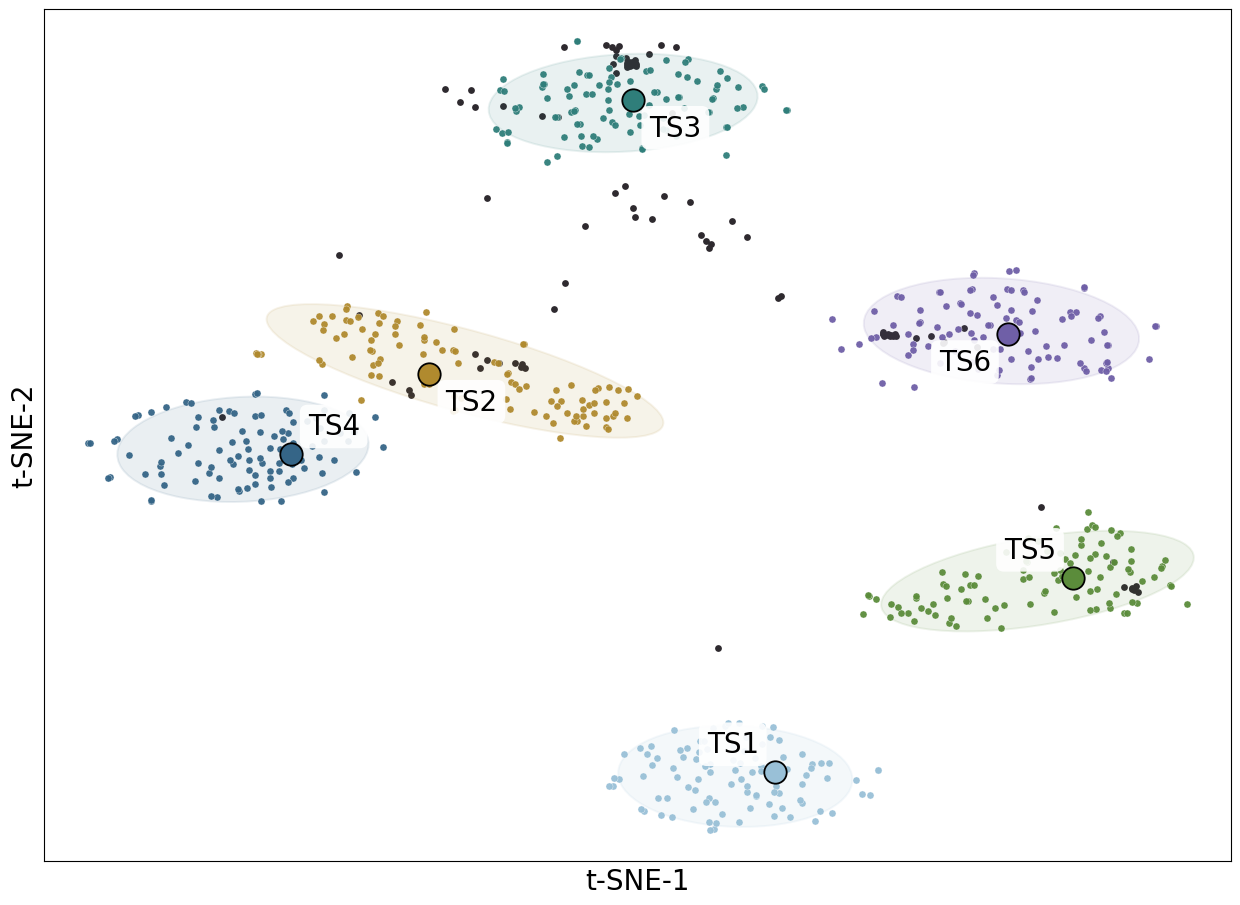

In [12]:
logger = logging.getLogger(__name__)


def seed_everything(seed: int, deterministic_torch: bool = True) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    if deterministic_torch:
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True
        torch.use_deterministic_algorithms(True, warn_only=False)


def stable_child_seed(base_seed: int, key: int) -> int:
    return int(
        np.random.SeedSequence([base_seed, key]).generate_state(1, dtype=np.uint32)[0]
    )


def spherical_mean(X: np.ndarray) -> np.ndarray:
    proto = X.mean(axis=0, dtype=np.float32)
    norm = np.linalg.norm(proto)
    if norm <= 1e-12:
        return np.ascontiguousarray(X[0], dtype=np.float32)
    return np.ascontiguousarray(proto / norm, dtype=np.float32)


@dataclass(frozen=True)
class TSNEPlotConfig:
    prototype_k: int = 3
    prototype_iters: int = 15
    tsne_max_perplexity: int = 40
    tsne_transform_k: int = 90
    tsne_n_components: int = 2
    tsne_n_jobs: int = 1
    tsne_neighbors: str = "exact"
    rotation_degrees: float = 0.0

    figure_size: tuple[float, float] = (13.5, 9.5)

    point_size: int = 26
    alpaca_point_size: int = 24
    prototype_size: int = 260

    alpaca_alpha: float = 1
    task_alpha: float = 0.95

    ellipse_alpha: float = 0.10
    ellipse_n_std: float = 1.85
    show_cluster_ellipses: bool = True

    annotate_prototypes: bool = True
    prototype_marker: str = "o"
    outlier_color: str = "#2E2A2F"
    outlier_label: str = "Outliers (Alpaca)"

    title_fontsize: int = 20
    axis_label_fontsize: int = 15
    prototype_label_fontsize: int = 13
    legend_fontsize: int = 13
    legend_title_fontsize: int = 20

    tsne_verbose: bool = True

    use_stable_task_prototype: bool = True


@dataclass
class TSNEPipelineResult:
    X2: np.ndarray
    X2_task: np.ndarray
    X2_alpaca: np.ndarray
    prototypes: np.ndarray
    prototype_X2: np.ndarray
    task_mask: np.ndarray
    alpaca_mask: np.ndarray
    y_task: np.ndarray
    prototype_task_ids_order: list[int]
    prototype_task_name_from_id: dict[int, str]
    embedding: Any
    fig: Optional[Figure] = None
    ax: Optional[Axes] = None


def build_task_name_from_id(
    task_ids: Mapping[str, int],
    task_id_to_name: Optional[Mapping[int, str]] = None,
) -> dict[int, str]:
    fallback = {int(v): str(k) for k, v in task_ids.items()}

    if task_id_to_name is None:
        return fallback

    result = fallback.copy()
    for tid, name in task_id_to_name.items():
        result[int(tid)] = str(name)

    return result


def build_task_color_from_id(
    task_ids: Mapping[str, int],
    task_colors: Mapping[str, str],
) -> dict[int, str]:
    task_color_from_id = {}

    for task_key, tid in task_ids.items():
        if task_key not in task_colors:
            raise ValueError(f"Missing color for task '{task_key}'")
        task_color_from_id[int(tid)] = task_colors[task_key]

    return task_color_from_id


def validate_inputs(
    X: np.ndarray,
    prompt_df: pd.DataFrame,
    task_ids: Mapping[str, int],
    task_colors: Mapping[str, str],
    config: TSNEPlotConfig,
    task_id_to_name: Optional[Mapping[int, str]] = None,
) -> None:
    if not isinstance(prompt_df, pd.DataFrame):
        raise TypeError("prompt_df must be a pandas.DataFrame")

    if "task_id" not in prompt_df.columns:
        raise ValueError("prompt_df must contain the 'task_id' column")

    X_np = np.asarray(X)
    if X_np.ndim != 2:
        raise ValueError(f"X must be a 2D matrix, found shape={X_np.shape}")

    if len(prompt_df) != X_np.shape[0]:
        raise ValueError(
            "Inconsistent number of rows between X and prompt_df: "
            f"{X_np.shape[0]} vs {len(prompt_df)}"
        )

    if X_np.shape[1] == 0:
        raise ValueError("X must have at least one feature")

    if not np.isfinite(X_np).all():
        raise ValueError("X contains NaN or infinity")

    if not task_ids:
        raise ValueError("task_ids cannot be empty")

    task_id_values = [int(v) for v in task_ids.values()]
    if any(tid < 0 for tid in task_id_values):
        raise ValueError("Configured task_id values must be >= 0")

    if len(set(task_id_values)) != len(task_id_values):
        raise ValueError("task_ids contains duplicate values")

    missing_colors = set(task_ids) - set(task_colors)
    if missing_colors:
        raise ValueError(f"Missing colors for tasks: {sorted(missing_colors)}")

    if task_id_to_name is not None:
        configured_task_ids = set(task_id_values)
        configured_names = {int(k) for k in task_id_to_name.keys()}
        missing_names = configured_task_ids - configured_names

        if missing_names:
            raise ValueError(
                "task_id_to_name does not contain names for these task IDs: "
                f"{sorted(missing_names)}"
            )

    configured_task_ids = set(task_id_values)
    observed_task_ids = set(
        prompt_df.loc[prompt_df["task_id"] >= 0, "task_id"].astype(np.int64).unique()
    )

    unknown_in_data = observed_task_ids - configured_task_ids
    if unknown_in_data:
        raise ValueError(
            "The dataset contains task_id values not present in task_ids: "
            f"{sorted(unknown_in_data)}"
        )

    missing_in_data = configured_task_ids - observed_task_ids
    if missing_in_data:
        raise ValueError(
            "task_ids contains tasks with no samples in the dataset: "
            f"{sorted(missing_in_data)}"
        )

    n_task_points = int((prompt_df["task_id"].to_numpy(dtype=np.int64) >= 0).sum())
    if n_task_points < 3:
        raise ValueError(
            f"At least 3 task samples are required for the t-SNE fit, found {n_task_points}"
        )

    if config.prototype_k < 1:
        raise ValueError("prototype_k must be >= 1")

    if config.prototype_iters < 1:
        raise ValueError("prototype_iters must be >= 1")

    if config.tsne_max_perplexity < 2:
        raise ValueError("tsne_max_perplexity must be >= 2")

    if config.tsne_transform_k < 1:
        raise ValueError("tsne_transform_k must be >= 1")

    if config.tsne_n_components != 2:
        raise ValueError("This plot supports only tsne_n_components=2")


def prepare_features(X: np.ndarray) -> np.ndarray:
    X_vis = np.asarray(X, dtype=np.float32, order="C")
    X_vis = normalize(X_vis, norm="l2", copy=False)
    return np.ascontiguousarray(X_vis, dtype=np.float32)


def build_masks_and_labels(
    prompt_df: pd.DataFrame,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    task_ids_all = prompt_df["task_id"].to_numpy(dtype=np.int64, copy=False)
    task_mask = task_ids_all >= 0
    alpaca_mask = ~task_mask
    y_task = task_ids_all[task_mask]
    return task_mask, alpaca_mask, y_task


def compute_tsne_perplexity(
    n_samples: int,
    max_perplexity: int,
) -> int:
    if n_samples < 3:
        raise ValueError(f"Too few points for t-SNE: n_samples={n_samples}")
    return min(max_perplexity, n_samples - 1)


def build_task_prototypes(
    X_vis: np.ndarray,
    task_mask: np.ndarray,
    y_task: np.ndarray,
    task_ids: Mapping[str, int],
    task_name_from_id: Mapping[int, str],
    spherical_kmeans_fn: Callable[[torch.Tensor, int, int], tuple[torch.Tensor, torch.Tensor]],
    k: int,
    iters: int,
    random_seed: int,
    use_stable_task_prototype: bool,
) -> tuple[np.ndarray, list[int], dict[int, str]]:
    task_ids_order = sorted(int(v) for v in task_ids.values())
    task_name_from_id = dict(task_name_from_id)

    X_tasks = X_vis[task_mask]
    n_features = X_vis.shape[1]
    prototypes = np.empty((len(task_ids_order), n_features), dtype=np.float32)

    indices_by_task_id = {
        tid: np.flatnonzero(y_task == tid)
        for tid in task_ids_order
    }

    for j, tid in enumerate(task_ids_order):
        idx = indices_by_task_id[tid]
        Xt_np = np.ascontiguousarray(X_tasks[idx], dtype=np.float32)

        if Xt_np.shape[0] == 0:
            raise ValueError(f"No sample found for task_id={tid}")

        if use_stable_task_prototype:
            prototypes[j] = spherical_mean(Xt_np)
            continue

        seed_everything(stable_child_seed(random_seed, tid))

        k_eff = min(k, Xt_np.shape[0])
        Xt = torch.from_numpy(Xt_np)

        centers, assign = spherical_kmeans_fn(
            Xt,
            k=k_eff,
            iters=iters,
        )

        assign = assign.to(torch.int64)
        counts = torch.bincount(assign, minlength=centers.size(0))
        dominant_cluster_idx = int(torch.argmax(counts).item())

        proto = (
            centers[dominant_cluster_idx]
            .detach()
            .cpu()
            .numpy()
            .astype(np.float32, copy=False)
        )
        proto /= max(np.linalg.norm(proto), 1e-12)
        prototypes[j] = proto

    return prototypes, task_ids_order, task_name_from_id


def fit_reference_tsne(
    X_task: np.ndarray,
    random_seed: int,
    config: TSNEPlotConfig,
) -> tuple[Any, np.ndarray]:
    perplexity = compute_tsne_perplexity(
        n_samples=len(X_task),
        max_perplexity=config.tsne_max_perplexity,
    )

    tsne = TSNE(
        n_components=config.tsne_n_components,
        perplexity=perplexity,
        metric="cosine",
        initialization="pca",
        random_state=random_seed,
        n_jobs=config.tsne_n_jobs,
        neighbors=config.tsne_neighbors,
        verbose=config.tsne_verbose,
    )

    embedding = tsne.fit(X_task)
    X2_task = np.asarray(embedding, dtype=np.float32)

    return embedding, X2_task


def transform_oos(
    embedding: Any,
    X_new: np.ndarray,
    n_reference: int,
    config: TSNEPlotConfig,
) -> np.ndarray:
    if X_new.shape[0] == 0:
        return np.zeros((0, config.tsne_n_components), dtype=np.float32)

    perplexity = compute_tsne_perplexity(
        n_samples=n_reference,
        max_perplexity=config.tsne_max_perplexity,
    )

    if config.tsne_transform_k < perplexity:
        raise ValueError(
            f"tsne_transform_k ({config.tsne_transform_k}) must be >= perplexity ({perplexity})"
        )

    k = min(config.tsne_transform_k, n_reference)

    X2_new = embedding.transform(
        X_new,
        perplexity=perplexity,
        initialization="median",
        k=k,
    )
    return np.asarray(X2_new, dtype=np.float32)


def assemble_full_embedding(
    n_samples: int,
    task_mask: np.ndarray,
    alpaca_mask: np.ndarray,
    X2_task: np.ndarray,
    X2_alpaca: np.ndarray,
    n_components: int,
) -> np.ndarray:
    X2 = np.zeros((n_samples, n_components), dtype=np.float32)
    X2[task_mask] = X2_task
    X2[alpaca_mask] = X2_alpaca
    return X2


def rotate_embedding_2d(
    points: np.ndarray,
    degrees: float,
    center: np.ndarray,
) -> np.ndarray:
    if float(degrees) % 360.0 == 0.0:
        return np.asarray(points, dtype=np.float32)

    theta = np.deg2rad(float(degrees))
    rotation = np.array(
        [[np.cos(theta), -np.sin(theta)],
         [np.sin(theta), np.cos(theta)]],
        dtype=np.float64,
    )
    centered = np.asarray(points, dtype=np.float64) - center
    return np.asarray(centered @ rotation.T + center, dtype=np.float32)


def _add_covariance_ellipse(
    ax: Axes,
    points: np.ndarray,
    color: str,
    n_std: float = 1.85,
    alpha: float = 0.10,
) -> None:
    if points.shape[0] < 3:
        return

    cov = np.cov(points.T)
    if cov.shape != (2, 2) or not np.isfinite(cov).all():
        return

    vals, vecs = np.linalg.eigh(cov)
    vals = np.clip(vals, 1e-8, None)

    order = vals.argsort()[::-1]
    vals = vals[order]
    vecs = vecs[:, order]

    angle = np.degrees(np.arctan2(vecs[1, 0], vecs[0, 0]))
    width, height = 2 * n_std * np.sqrt(vals)

    ellipse = Ellipse(
        xy=points.mean(axis=0),
        width=width,
        height=height,
        angle=angle,
        facecolor=color,
        edgecolor=color,
        linewidth=1.4,
        alpha=alpha,
        zorder=1,
    )
    ax.add_patch(ellipse)


def _prototype_label_offset(
    point: np.ndarray,
    global_center: np.ndarray,
) -> tuple[int, int, str, str]:
    dx = 12 if point[0] <= global_center[0] else -12
    dy = 10 if point[1] <= global_center[1] else -10
    ha = "left" if dx > 0 else "right"
    va = "bottom" if dy > 0 else "top"
    return dx, dy, ha, va


def plot_tsne_2d(
    X2: np.ndarray,
    prompt_df: pd.DataFrame,
    task_ids: Mapping[str, int],
    task_color_from_id: Mapping[int, str],
    alpaca_mask: np.ndarray,
    prototype_X2: np.ndarray,
    prototype_task_ids_order: list[int],
    prototype_task_name_from_id: Mapping[int, str],
    config: TSNEPlotConfig,
    title: str = "Task-reference t-SNE",
    show: bool = True,
) -> tuple[Figure, Axes]:
    fig, ax = plt.subplots(figsize=config.figure_size)
    task_ids_all = prompt_df["task_id"].to_numpy(dtype=np.int64, copy=False)

    if np.any(alpaca_mask):
        ax.scatter(
            X2[alpaca_mask, 0],
            X2[alpaca_mask, 1],
            s=config.alpaca_point_size,
            alpha=config.alpaca_alpha,
            color=config.outlier_color,
            label=config.outlier_label,
            linewidths=0,
            rasterized=True,
            zorder=0,
        )

    for _, tid in sorted(task_ids.items(), key=lambda item: item[1]):
        tid = int(tid)
        task_name = prototype_task_name_from_id[tid]

        mask = task_ids_all == tid
        pts = X2[mask]

        if pts.shape[0] == 0:
            continue

        color = task_color_from_id[tid]

        if config.show_cluster_ellipses:
            _add_covariance_ellipse(
                ax=ax,
                points=pts,
                color=color,
                n_std=config.ellipse_n_std,
                alpha=config.ellipse_alpha,
            )

        ax.scatter(
            pts[:, 0],
            pts[:, 1],
            s=config.point_size,
            alpha=config.task_alpha,
            color=color,
            label=task_name,
            edgecolors="white",
            linewidths=0.25,
            rasterized=True,
            zorder=3,
        )

    global_center = X2.mean(axis=0)

    for j, tid in enumerate(prototype_task_ids_order):
        tid = int(tid)
        task_name = prototype_task_name_from_id[tid]
        px, py = prototype_X2[j]
        color = task_color_from_id[tid]

        ax.scatter(
            [px],
            [py],
            s=config.prototype_size,
            marker=config.prototype_marker,
            color=color,
            edgecolors="black",
            linewidths=1.3,
            zorder=6,
        )

        if config.annotate_prototypes:
            dx, dy, ha, va = _prototype_label_offset(
                np.array([px, py], dtype=np.float32),
                global_center=global_center,
            )
        centroid_label = task_name.split(":", 1)[0].strip()
        
        ax.annotate(
            centroid_label,
            xy=(px, py),
            xytext=(dx, dy),
            textcoords="offset points",
            ha=ha,
            va=va,
            fontsize=config.prototype_label_fontsize,
            fontweight="normal",
            color="black",
            bbox=dict(
                boxstyle="round,pad=0.28",
                fc="white",
                ec="none",
                alpha=0.90,
            ),
            zorder=7,
        )

    ax.set_title(title, pad=14, fontsize=config.title_fontsize, fontweight="bold")
    ax.set_xlabel("t-SNE-1", fontsize=config.axis_label_fontsize)
    ax.set_ylabel("t-SNE-2", fontsize=config.axis_label_fontsize)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    ax.margins(0.04)

    handles, labels = ax.get_legend_handles_labels()
    handle_from_label = dict(zip(labels, handles))

    ordered_task_ids = [2, 1, 5, 3, 4, 0]

    ordered_labels = [
        prototype_task_name_from_id[tid]
        for tid in ordered_task_ids
        if tid in prototype_task_name_from_id
    ]

    if config.outlier_label in handle_from_label:
        ordered_labels.append(config.outlier_label)

    ordered_handles = [
        handle_from_label[label]
        for label in ordered_labels
        if label in handle_from_label
    ]

    ordered_labels = [
        label
        for label in ordered_labels
        if label in handle_from_label
    ]

    legend = ax.legend(
        ordered_handles,
        ordered_labels,
        loc="lower right",
        bbox_to_anchor=(1.1, -0.1),
        title=None,
        frameon=True,
        framealpha=0.92,
        borderaxespad=0.2,
        prop={
            "size": config.legend_fontsize,
        },
        markerscale=1.25,
    )

    if legend is not None:
        legend.get_title().set_fontweight("bold")

    fig.tight_layout()

    if show:
        plt.show()

    return fig, ax


def run_task_reference_tsne(
    X: np.ndarray,
    prompt_df: pd.DataFrame,
    task_ids: Mapping[str, int],
    task_colors: Mapping[str, str],
    random_seed: int,
    spherical_kmeans_fn: Callable[[torch.Tensor, int, int], tuple[torch.Tensor, torch.Tensor]],
    task_id_to_name: Optional[Mapping[int, str]] = None,
    config: Optional[TSNEPlotConfig] = None,
    plot: bool = True,
    plot_title: str = "Task-reference t-SNE",
) -> TSNEPipelineResult:
    config = config or TSNEPlotConfig()

    seed_everything(random_seed)

    validate_inputs(
        X=X,
        prompt_df=prompt_df,
        task_ids=task_ids,
        task_colors=task_colors,
        config=config,
        task_id_to_name=task_id_to_name,
    )

    task_name_from_id = build_task_name_from_id(
        task_ids=task_ids,
        task_id_to_name=task_id_to_name,
    )

    task_color_from_id = build_task_color_from_id(
        task_ids=task_ids,
        task_colors=task_colors,
    )

    X_vis = prepare_features(X)
    task_mask, alpaca_mask, y_task = build_masks_and_labels(prompt_df)

    logger.info(
        "n_tasks=%d | n_task_prompts=%d | n_outliers=%d",
        len(task_ids),
        int(task_mask.sum()),
        int(alpaca_mask.sum()),
    )

    prototypes, prototype_task_ids_order, prototype_task_name_from_id = build_task_prototypes(
        X_vis=X_vis,
        task_mask=task_mask,
        y_task=y_task,
        task_ids=task_ids,
        task_name_from_id=task_name_from_id,
        spherical_kmeans_fn=spherical_kmeans_fn,
        k=config.prototype_k,
        iters=config.prototype_iters,
        random_seed=random_seed,
        use_stable_task_prototype=config.use_stable_task_prototype,
    )
    logger.info("prototypes shape=%s", prototypes.shape)

    X_task = X_vis[task_mask]
    X_alpaca = X_vis[alpaca_mask]

    embedding_task, X2_task = fit_reference_tsne(
        X_task=X_task,
        random_seed=random_seed,
        config=config,
    )
    logger.info("X2_task shape=%s", X2_task.shape)

    X2_alpaca = transform_oos(
        embedding=embedding_task,
        X_new=X_alpaca,
        n_reference=len(X_task),
        config=config,
    )
    logger.info("X2_outliers shape=%s", X2_alpaca.shape)

    prototype_X2 = transform_oos(
        embedding=embedding_task,
        X_new=prototypes,
        n_reference=len(X_task),
        config=config,
    )
    logger.info("prototype_X2 shape=%s", prototype_X2.shape)

    X2 = assemble_full_embedding(
        n_samples=len(X_vis),
        task_mask=task_mask,
        alpaca_mask=alpaca_mask,
        X2_task=X2_task,
        X2_alpaca=X2_alpaca,
        n_components=config.tsne_n_components,
    )
    logger.info("X2 full shape=%s", X2.shape)

    rotation_center = X2.mean(axis=0, dtype=np.float64)
    X2 = rotate_embedding_2d(X2, config.rotation_degrees, rotation_center)
    prototype_X2 = rotate_embedding_2d(
        prototype_X2, config.rotation_degrees, rotation_center
    )
    X2_task = np.ascontiguousarray(X2[task_mask], dtype=np.float32)
    X2_alpaca = np.ascontiguousarray(X2[alpaca_mask], dtype=np.float32)
    logger.info("Applied rigid plot rotation: %.1f degrees", config.rotation_degrees)

    fig = None
    ax = None
    if plot:
        fig, ax = plot_tsne_2d(
            X2=X2,
            prompt_df=prompt_df,
            task_ids=task_ids,
            task_color_from_id=task_color_from_id,
            alpaca_mask=alpaca_mask,
            prototype_X2=prototype_X2,
            prototype_task_ids_order=prototype_task_ids_order,
            prototype_task_name_from_id=prototype_task_name_from_id,
            config=config,
            title=plot_title,
            show=False,
        )

    return TSNEPipelineResult(
        X2=X2,
        X2_task=X2_task,
        X2_alpaca=X2_alpaca,
        prototypes=prototypes,
        prototype_X2=prototype_X2,
        task_mask=task_mask,
        alpaca_mask=alpaca_mask,
        y_task=y_task,
        prototype_task_ids_order=prototype_task_ids_order,
        prototype_task_name_from_id=prototype_task_name_from_id,
        embedding=embedding_task,
        fig=fig,
        ax=ax,
    )


RANDOM_SEED = 42

TASK_ID_TO_NAME = {
    0: "TS6: Normalization",
    1: "TS2: Detoxify language",
    2: "TS1: Positive tone",
    3: "TS4: Polite style",
    4: "TS5: Virginia Woolf style",
    5: "TS3: Objective style",
}

result = run_task_reference_tsne(
    X=X,
    prompt_df=prompt_df,
    task_ids=TASK_IDS,
    task_colors=TASK_COLORS,
    task_id_to_name=TASK_ID_TO_NAME,
    random_seed=RANDOM_SEED,
    spherical_kmeans_fn=AtasVectorMediator._spherical_kmeans,
    config=TSNEPlotConfig(
        prototype_k=3,
        prototype_iters=15,
        tsne_max_perplexity=40,
        tsne_transform_k=90,
        tsne_n_components=2,
        tsne_n_jobs=1,
        tsne_neighbors="exact",
        rotation_degrees=108.0,
        figure_size=(13.5, 9.5),
        point_size=26,
        alpaca_point_size=24,
        prototype_size=260,

        alpaca_alpha=1,
        task_alpha=0.95,
        ellipse_alpha=0.10,
        ellipse_n_std=1.85,
        show_cluster_ellipses=True,
        annotate_prototypes=True,
        prototype_marker="o",
        outlier_color="#2E2A2F",
        outlier_label="ALPACA",

        title_fontsize=20,
        axis_label_fontsize=20,
        prototype_label_fontsize=20,
        legend_fontsize=20,
        legend_title_fontsize=20,

        tsne_verbose=True,
        use_stable_task_prototype=True,
    ),
    plot=True,
    plot_title="",
)
legend = result.ax.get_legend()
if legend is not None:
    legend.remove()

folder = "plots"
os.makedirs(folder, exist_ok=True)

file_path = os.path.join(folder, "qwen_2_5_clustering.png")

result.fig.savefig(
    file_path,
    dpi=300,
    bbox_inches="tight",
)

print(f"Plot saved to: {file_path}")
plt.show()

# Best Layer

Best-layer dataset shape: 600 | no_alpaca: True
X_all shape: (600, 21504) | len(used_layers): 24 | d: 896


Best by silhouette: 14 sil= 0.34066641330718994
Best by ARI: 10 ARI= 0.9903959613205222


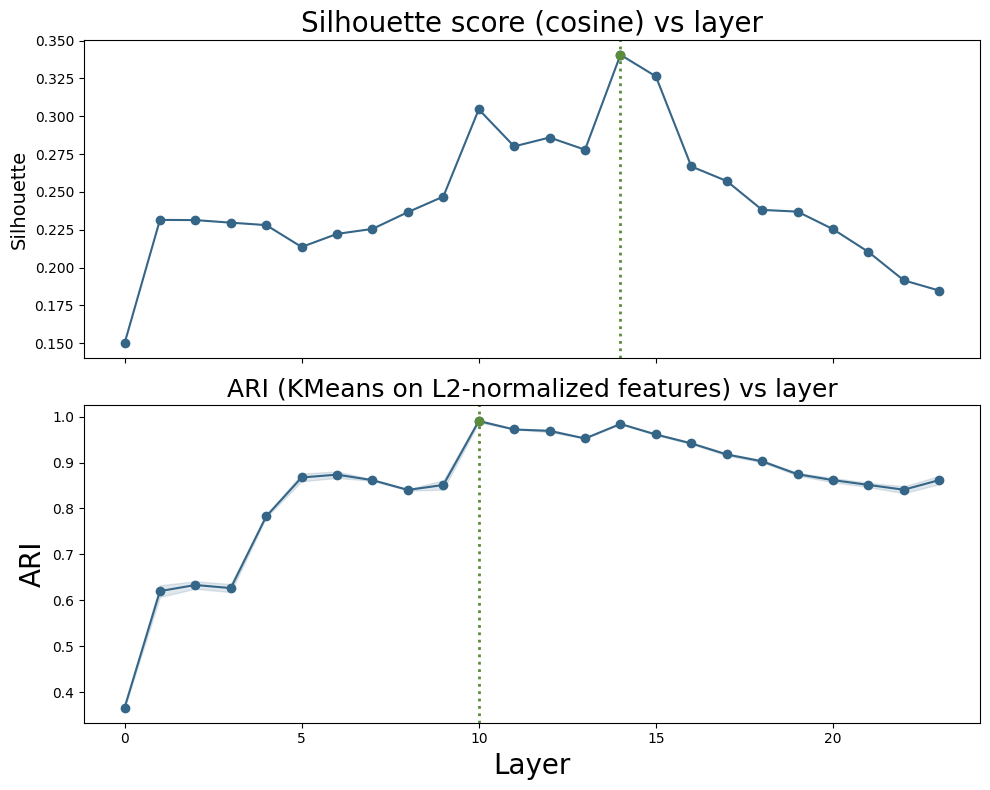

In [13]:
def to_numpy(X):
    import torch
    if torch.is_tensor(X):
        return X.detach().cpu().numpy()
    return X


def infer_d_from_concat(X2d, used_layers):
    if X2d.shape[1] % len(used_layers) != 0:
        raise ValueError(
            f"X.shape[1]={X2d.shape[1]} not divisible by len(used_layers)={len(used_layers)}"
        )
    return X2d.shape[1] // len(used_layers)


def get_layer_matrix(X_all, layer_id, used_layers, d=None):
    X_all = to_numpy(X_all)

    if isinstance(X_all, np.ndarray) and X_all.ndim == 3:
        return X_all[:, int(layer_id), :]

    if isinstance(X_all, np.ndarray) and X_all.ndim == 2:
        if d is None:
            d = infer_d_from_concat(X_all, used_layers)
        k = used_layers.index(int(layer_id))
        return X_all[:, k * d: (k + 1) * d]

    if isinstance(X_all, list):
        k = used_layers.index(int(layer_id))
        return to_numpy(X_all[k])

    raise TypeError(
        f"Unrecognized X_all format: type={type(X_all)}, ndim={getattr(X_all, 'ndim', None)}"
    )


def silhouette_cosine(X, y, sample_size=2000, seed=0):
    Xn = normalize(X, norm="l2")
    n = Xn.shape[0]
    if n < 3 or len(np.unique(y)) < 2:
        return np.nan
    ss = min(sample_size, n)
    return silhouette_score(Xn, y, metric="cosine", sample_size=ss, random_state=seed)


def ari_kmeans(
        X,
        y,
        n_clusters=None,
        seeds=(0, 1, 2, 3, 4),
        n_init=20,
        use_l2_norm=True,
):
    X = np.asarray(X)
    y = np.asarray(y)

    classes = np.unique(y)
    if X.shape[0] < 2 or classes.size < 2:
        return np.nan, np.nan

    if n_clusters is None:
        n_clusters = classes.size

    X_proc = normalize(X, norm="l2") if use_l2_norm else StandardScaler().fit_transform(X)

    scores = []
    for seed in seeds:
        km = KMeans(
            n_clusters=n_clusters,
            init="k-means++",
            n_init=n_init,
            random_state=int(seed),
            algorithm="lloyd",
        )
        y_pred = km.fit_predict(X_proc)
        scores.append(adjusted_rand_score(y, y_pred))

    return float(np.mean(scores)), float(np.std(scores))


n_layers = int(model.config.num_hidden_layers)
all_layers = list(range(n_layers))

X_all, used_layers = extract_prompt_last_token_vectors(
    model=model,
    tokenizer=tokenizer,
    prompts=best_layer_prompt_df["prompt"].tolist(),
    layers_to_extract=all_layers,
    batch_size=BATCH_SIZE,
    max_len=MAX_LEN,
    gc_every=50,
)

y = best_layer_prompt_df["task_id"].to_numpy()

X_all = to_numpy(X_all)
if isinstance(X_all, np.ndarray) and X_all.ndim == 2:
    d = infer_d_from_concat(X_all, used_layers)
elif isinstance(X_all, np.ndarray) and X_all.ndim == 3:
    d = X_all.shape[2]
else:
    d = None

print(
    "Best-layer dataset shape:",
    len(best_layer_prompt_df),
    "| no_alpaca:",
    bool((best_layer_prompt_df["task_id"].to_numpy(dtype=int) >= 0).all()),
)
print("X_all shape:", getattr(X_all, "shape", None), "| len(used_layers):", len(used_layers), "| d:", d)

BASE_SEED = 0
SIL_SAMPLE = 2000

sil = []
ari_mean = []
ari_std = []

n_clusters = len(np.unique(y))

for li in used_layers:
    Xl = get_layer_matrix(X_all, li, used_layers, d=d)

    sil.append(silhouette_cosine(Xl, y, sample_size=SIL_SAMPLE, seed=BASE_SEED))

    ari_m, ari_s = ari_kmeans(
        Xl,
        y,
        n_clusters=n_clusters,
        seeds=(0, 1, 2, 3, 4),
        n_init=20,
        use_l2_norm=True,
    )
    ari_mean.append(ari_m)
    ari_std.append(ari_s)

sil = np.asarray(sil)
ari_mean = np.asarray(ari_mean)
ari_std = np.asarray(ari_std)

best_sil_layer = int(used_layers[int(np.nanargmax(sil))]) if np.any(~np.isnan(sil)) else None
best_ari_layer = int(used_layers[int(np.nanargmax(ari_mean))]) if np.any(~np.isnan(ari_mean)) else None

print("Best by silhouette:", best_sil_layer, "sil=", float(np.nanmax(sil)) if best_sil_layer is not None else np.nan)
print("Best by ARI:", best_ari_layer, "ARI=", float(np.nanmax(ari_mean)) if best_ari_layer is not None else np.nan)

LINE_COLOR = "#356587"
BEST_COLOR = "#5B8C3B"
fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

ax = axes[0]
ax.plot(
    used_layers, sil,
    marker="o",
    color=LINE_COLOR,
    markerfacecolor=LINE_COLOR,
    markeredgecolor=LINE_COLOR
)

if best_sil_layer is not None:
    ax.axvline(best_sil_layer, color=BEST_COLOR, linestyle=":", linewidth=2)
    best_sil_i = int(np.nanargmax(sil))
    ax.scatter([used_layers[best_sil_i]], [sil[best_sil_i]], color=BEST_COLOR, zorder=3)

ax.set_title("Silhouette score (cosine) vs layer", fontsize=20)
ax.set_ylabel("Silhouette", fontsize=14)

ax = axes[1]
ax.plot(
    used_layers, ari_mean,
    marker="o",
    color=LINE_COLOR,
    markerfacecolor=LINE_COLOR,
    markeredgecolor=LINE_COLOR
)

ax.fill_between(
    used_layers,
    ari_mean - ari_std,
    ari_mean + ari_std,
    alpha=0.15,
    color=LINE_COLOR
)

if best_ari_layer is not None:
    ax.axvline(best_ari_layer, color=BEST_COLOR, linestyle=":", linewidth=2)
    best_ari_i = int(np.nanargmax(ari_mean))
    ax.scatter([used_layers[best_ari_i]], [ari_mean[best_ari_i]], color=BEST_COLOR, zorder=3)

ax.set_title("ARI (KMeans on L2-normalized features) vs layer", fontsize=18)
ax.set_xlabel("Layer", fontsize=20)
ax.set_ylabel("ARI", fontsize=20)

plt.tight_layout()
folder = "plots"

file_path = os.path.join(folder, "qwen_2_5_best_layers.png")
fig.savefig(file_path, dpi=300, bbox_inches="tight")

plt.show()

# Testing task selection with refusal on validation splits

In [14]:
COLORS = ["#6F5FA7", "#B08A2E", "#99C0D7", "#356587", "#5B8C3B"]

ATAS_LAYER = int(math.ceil((NUM_LAYERS - 1) / 2))
ATAS_ALPHA_SEED = int(globals().get("RANDOM_SEED", 42))
ATAS_SPLIT_SEED = int(globals().get("RANDOM_SEED", 42))
ATAS_EVAL_BATCH_SIZE = int(globals().get("BATCH_SIZE", 16))
ATAS_TRAIN_PER_TASK = int(PROMPT_VARIANT_COUNT)
OOD_SEED = 42

REJECTION_ALPHAS = [round(x, 2) for x in np.arange(0.30, 1.001, 0.05)]

_task_ids_order = sorted(int(v) for v in TASK_IDS.values())
_task_name_from_id = {int(v): k for k, v in TASK_IDS.items()}

_rng = np.random.default_rng(ATAS_ALPHA_SEED)
alpha_random = {
    tid: float(val)
    for tid, val in zip(_task_ids_order, _rng.uniform(0.05, 1.0, size=len(_task_ids_order)))
}


def build_task_dataset_teacher_forcing_df(
        samples_per_task: int,
        seed: int = 0,
        split: str = "train",
) -> pd.DataFrame:
    frames = []
    for task_name, tid in TASK_IDS.items():
        if split == "train":
            sampled = _shared_balanced_train_df(task_name, samples_per_task)
        else:
            base_df = build_task_df(task_name, split).copy().reset_index(drop=True)
            sampled = _sample_rows_exact(base_df, int(samples_per_task), seed=int(seed) + 4000 + int(tid))
        tf_df = to_teacher_forcing_df(sampled, task_name, split=split)
        tf_df["task_name"] = task_name
        tf_df["split"] = split
        frames.append(tf_df)
    return (
        pd.concat(frames, ignore_index=True)
        .sample(frac=1.0, random_state=int(seed))
        .reset_index(drop=True)
    )


atas_executor_train_df = build_task_dataset_teacher_forcing_df(
    samples_per_task=ATAS_TRAIN_PER_TASK,
    seed=ATAS_SPLIT_SEED,
    split="train",
)

in_domain_eval_df = build_task_validation_prompt_df(seed=int(ATAS_SPLIT_SEED) + 2000)
ood_eval_df = build_alpaca_prompt_df(
    samples=None,
    seed=OOD_SEED,
    split="validation",
)

atas_executor = Executor(
    model=model,
    tokenizer=tokenizer,
    train_df=atas_executor_train_df,
    mediator_type=MediatorTypeEnum.ATAS_CMD,
    layers_to_extract=[int(ATAS_LAYER)],
    atas_master_layer=int(ATAS_LAYER),
    batch_size=int(ATAS_EVAL_BATCH_SIZE),
    padding_side=tokenizer.padding_side,
    truncation_side=getattr(tokenizer, "truncation_side", "left"),
    dtype=getattr(model, "dtype", torch.float32),
    alpha=dict(alpha_random),
    generation_kwargs={},
    atas_similarity_threshold=0.0,
    tokens_window=-1,
    task_type=TaskTypeEnum.UNSUPERVISED,
    apply_from_token=-1,
    apply_from_mode=ApplyFromModeEnum.PROMPT_END,
    atas_use_last_token_for_prompt=True,
    use_last_token_for_response=True,
    decode_chunk_max=1,
    free_training_artifacts_after_build=True,
)

_ = atas_executor.representation_extractor()

atas_training_strategy = atas_executor.steering_strategy
if not isinstance(atas_training_strategy, AtasSteeringStrategy):
    raise RuntimeError(
        f"Expected AtasSteeringStrategy, got {type(atas_training_strategy).__name__}"
    )

routing_centroids, correction_vectors, trained_task_ids = atas_training_strategy.export_params()
pc = routing_centroids[int(ATAS_LAYER)]
if not torch.is_tensor(pc):
    pc = torch.tensor(pc, dtype=torch.float32)

centroid_norms = torch.linalg.norm(pc.to(torch.float32), dim=-1).cpu().numpy()
display(
    pd.DataFrame({
        "task_id": trained_task_ids,
        "centroid_norm": centroid_norms
    }).round(6)
)

print(
    "Centroid norms summary:",
    {
        "min": float(np.min(centroid_norms)),
        "max": float(np.max(centroid_norms)),
        "mean": float(np.mean(centroid_norms)),
    }
)
trained_task_ids = [int(t) for t in trained_task_ids]
if sorted(trained_task_ids) != sorted(_task_ids_order):
    raise RuntimeError(
        f"Executor produced ATAS task_ids {trained_task_ids}, expected {_task_ids_order}"
    )

print("ATAS_LAYER:", ATAS_LAYER)
print("ATAS_TRAIN_PER_TASK:", ATAS_TRAIN_PER_TASK, "(teacher-forcing rows per task for Executor)")
print("ATAS training rows:", len(atas_executor_train_df))
print("In-domain validation prompts:", len(in_domain_eval_df))
print("OOD Alpaca validation prompts:", len(ood_eval_df))
print("alpha_random:", alpha_random)
print("Routing centroid shape:", tuple(routing_centroids[int(ATAS_LAYER)].shape))
print("Correction vector shape:", tuple(correction_vectors[int(ATAS_LAYER)].shape))

display(
    atas_executor_train_df[["task_name", "split"]]
    .value_counts()
    .rename("count")
    .reset_index()
    .head(20)
)

Extracting activations:   0%|          | 0/38 [00:00<?, ?it/s]

You're using a Qwen2TokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.


Executor teacher forcing capped 14/600 responses at 512 tokens (longest before truncation: 926).


,task_id,centroid_norm
0,0,0.999998
1,1,1.000024
2,2,0.999887
3,3,1.000049
4,4,0.999885
5,5,1.000048


Centroid norms summary: {'min': 0.9998847246170044, 'max': 1.000049114227295, 'mean': 0.9999816417694092}
ATAS_LAYER: 12
ATAS_TRAIN_PER_TASK: 100 (teacher-forcing rows per task for Executor)
ATAS training rows: 600
In-domain validation prompts: 2400
OOD Alpaca validation prompts: 400
alpha_random: {0: 0.7852582461281652, 1: 0.46693451776444966, 2: 0.8656680239158133, 3: 0.7124996276063957, 4: 0.13946848049326704, 5: 0.9768412340549182}
Routing centroid shape: (6, 896)
Correction vector shape: (6, 896)


,task_name,split,count
0,authormix_woolf_style,train,100
1,imdb_positive_sentiment,train,100
2,libritts_text_original_to_normalized,train,100
3,paradetox_non_toxic,train,100
4,setfit_subj_objective,train,100
5,stanford_politeness_polite,train,100


In [15]:
def extract_single_layer_prompt_vectors(df: pd.DataFrame, layer_id: int) -> np.ndarray:
    if df is None or len(df) == 0:
        return np.zeros((0, 0), dtype=np.float32)

    X_layer, used_layers_local = extract_prompt_last_token_vectors(
        model=model,
        tokenizer=tokenizer,
        prompts=df["prompt"].tolist(),
        layers_to_extract=[int(layer_id)],
        batch_size=ATAS_EVAL_BATCH_SIZE,
        max_len=MAX_LEN,
        gc_every=50,
        decode_chunk_max=1,
        use_last_token_for_prompt=bool(atas_training_strategy.use_last_token_for_prompt),
    )

    X_layer = np.asarray(X_layer, dtype=np.float32)
    if X_layer.ndim == 3:
        X_layer = X_layer[:, 0, :]
    return X_layer

def _route_prompt_vectors_public(
        X_layer: np.ndarray,
        *,
        layer_id: int,
        similarity_threshold: float,
        batch_size: int,
) -> pd.DataFrame:
    if X_layer is None or len(X_layer) == 0:
        return pd.DataFrame(
            {
                "pred_task_id": np.asarray([], dtype=int),
                "routing_similarity": np.asarray([], dtype=np.float32),
                "selected": np.asarray([], dtype=bool),
            }
        )

    pc = routing_centroids[int(layer_id)]
    if not torch.is_tensor(pc):
        pc = torch.tensor(pc, dtype=torch.float32)

    pc = pc.detach().to(torch.float32).contiguous()
    if pc.ndim != 2:
        raise RuntimeError(
            f"Expected routing centroids with shape [K, H], got {tuple(pc.shape)}"
        )

    pc_norms = torch.linalg.norm(pc, dim=-1)
    if torch.any(pc_norms <= 1e-12):
        raise RuntimeError(
            f"Found zero-norm routing centroid(s) at layer {layer_id}: {pc_norms.tolist()}"
        )

    pc_n = torch.nn.functional.normalize(pc, dim=-1, eps=1e-12)

    pred_task_ids = []
    routing_sims = []
    selected_mask = []

    for i in range(0, len(X_layer), int(batch_size)):
        xb = torch.as_tensor(
            X_layer[i: i + int(batch_size)],
            dtype=torch.float32,
        )

        if xb.ndim != 2:
            raise RuntimeError(
                f"Expected prompt vectors with shape [B, H], got {tuple(xb.shape)}"
            )

        xb_norms = torch.linalg.norm(xb, dim=-1)
        if torch.any(xb_norms <= 1e-12):
            raise RuntimeError(
                f"Found zero-norm prompt vector(s) in batch starting at index {i}"
            )

        xb_n = torch.nn.functional.normalize(xb, dim=-1, eps=1e-12)
        sims = xb_n @ pc_n.transpose(0, 1)

        routing_sim, routing_idx = sims.max(dim=-1)

        if float(similarity_threshold) <= 0.0:
            sel = torch.ones_like(routing_idx, dtype=torch.bool)
        else:
            sel = routing_sim >= float(similarity_threshold)

        pred_task_ids.extend(
            [trained_task_ids[int(k)] for k in routing_idx.detach().cpu().tolist()]
        )
        routing_sims.extend(
            routing_sim.detach().cpu().numpy().astype(np.float32).tolist()
        )
        selected_mask.extend(
            sel.detach().cpu().numpy().astype(bool).tolist()
        )

    return pd.DataFrame(
        {
            "pred_task_id": np.asarray(pred_task_ids, dtype=int),
            "routing_similarity": np.asarray(routing_sims, dtype=np.float32),
            "selected": np.asarray(selected_mask, dtype=bool),
        }
    )

def run_atas_router_on_vectors(
        X_layer: np.ndarray,
        similarity_threshold: float,
) -> pd.DataFrame:
    return _route_prompt_vectors_public(
        X_layer=X_layer,
        layer_id=int(atas_training_strategy.master_prompt_layer),
        similarity_threshold=float(similarity_threshold),
        batch_size=int(ATAS_EVAL_BATCH_SIZE),
    )


X_in_domain_eval = extract_single_layer_prompt_vectors(in_domain_eval_df, ATAS_LAYER)
X_ood_eval = extract_single_layer_prompt_vectors(ood_eval_df, ATAS_LAYER)

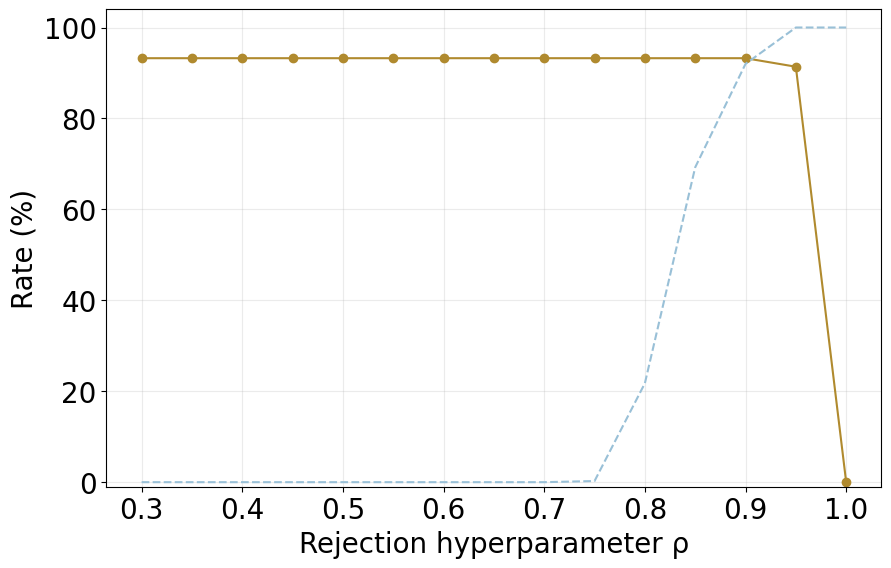

In [16]:
def evaluate_threshold(threshold: float) -> Dict[str, float]:
    in_domain_pred = run_atas_router_on_vectors(
        X_layer=X_in_domain_eval,
        similarity_threshold=threshold,
    )
    in_domain_eval = in_domain_eval_df[["task_id", "task_name"]].reset_index(drop=True).copy()
    in_domain_eval["pred_task_id"] = in_domain_pred["pred_task_id"].to_numpy(dtype=int)
    in_domain_eval["routing_similarity"] = in_domain_pred["routing_similarity"].to_numpy(dtype=np.float32)
    in_domain_eval["selected"] = in_domain_pred["selected"].to_numpy(dtype=bool)

    ood_pred = run_atas_router_on_vectors(
        X_layer=X_ood_eval,
        similarity_threshold=threshold,
    )

    in_domain_total = int(len(in_domain_eval))
    ood_total = int(len(ood_pred))

    in_domain_selected = int(in_domain_eval["selected"].sum())
    in_domain_rejected = int(in_domain_total - in_domain_selected)
    in_domain_correct = int(
        (
            in_domain_eval["selected"]
            & (in_domain_eval["pred_task_id"] == in_domain_eval["task_id"])
        ).sum()
    )
    in_domain_wrong_routing = int(in_domain_selected - in_domain_correct)
    ood_refused = int((~ood_pred["selected"]).sum())

    return {
        "rejection_alpha": float(threshold),
        "in_domain_total": in_domain_total,
        "in_domain_selected": in_domain_selected,
        "in_domain_rejected": in_domain_rejected,
        "in_domain_correct": in_domain_correct,
        "in_domain_wrong_routing": in_domain_wrong_routing,
        "global_routing_accuracy_pct": 100.0 * in_domain_correct / max(in_domain_total, 1),
        "selected_routing_accuracy_pct": 100.0 * in_domain_correct / max(in_domain_selected, 1),
        "ood_total": ood_total,
        "ood_refused": ood_refused,
        "ood_refusal_pct": 100.0 * ood_refused / max(ood_total, 1),
    }


atas_sweep_df = pd.DataFrame([evaluate_threshold(alpha) for alpha in REJECTION_ALPHAS])
atas_sweep_df = atas_sweep_df.sort_values("rejection_alpha").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, 6.2))

ax.plot(
    atas_sweep_df["rejection_alpha"],
    atas_sweep_df["global_routing_accuracy_pct"],
    marker="o",
    color=COLORS[1],
    markerfacecolor=COLORS[1],
    markeredgecolor=COLORS[1],
    label="Selection accuracy (in-domain)",
)

ax.plot(
    atas_sweep_df["rejection_alpha"],
    atas_sweep_df["ood_refusal_pct"],
    linestyle="--",
    color=COLORS[2],
    label="Refusal (ood)",
)

ax.set_xlabel("Rejection hyperparameter ρ", fontsize=20)
ax.set_ylabel("Rate (%)", fontsize=20)

ax.tick_params(axis="both", labelsize=20)

ax.set_ylim(-1, 104)
ax.grid(True, alpha=0.25)

folder = "plots"

file_path = os.path.join(folder, "qwen_2_5_accuracy_vs_rho.png")
fig.savefig(file_path, dpi=300, bbox_inches="tight")

plt.show()

In [17]:
required_names = [
    "atas_sweep_df",
    "run_atas_router_on_vectors",
    "extract_single_layer_prompt_vectors",
    "build_alpaca_prompt_df",
    "test_by_task",
    "TASK_IDS",
    "_finalize_prompt_frame",
    "ATAS_LAYER",
]
missing = [name for name in required_names if name not in globals()]
if missing:
    raise RuntimeError(
        "Required variables/functions are missing. "
        "Run all cells in the ATAS validation section first. "
        f"Missing: {missing}"
    )

validation_required_cols = {
    "rejection_alpha",
    "global_routing_accuracy_pct",
    "ood_refusal_pct",
}
missing_cols = validation_required_cols.difference(atas_sweep_df.columns)
if missing_cols:
    raise RuntimeError(
        "atas_sweep_df does not contain the expected columns. "
        f"Missing columns: {sorted(missing_cols)}"
    )

validation_rho_candidates = atas_sweep_df.copy().reset_index(drop=True)

validation_rho_candidates["validation_balanced_score"] = np.minimum(
    validation_rho_candidates["global_routing_accuracy_pct"].astype(float),
    validation_rho_candidates["ood_refusal_pct"].astype(float),
)

best_validation_rho_row = (
    validation_rho_candidates
    .sort_values(
        by=[
            "validation_balanced_score",
            "global_routing_accuracy_pct",
            "ood_refusal_pct",
            "rejection_alpha",
        ],
        ascending=[False, False, False, True],
    )
    .iloc[0]
    .copy()
)

BEST_VALIDATION_RHO = float(best_validation_rho_row["rejection_alpha"])

atas_executor.atas_similarity_threshold = BEST_VALIDATION_RHO
atas_training_strategy.similarity_threshold = BEST_VALIDATION_RHO

print(f"Best ρ selected on validation: {BEST_VALIDATION_RHO:.4f}")

def build_task_test_prompt_df_all(seed: int = 0) -> pd.DataFrame:
    """Build the in-domain test set from all examples available in test_by_task."""
    frames = []

    for task_name in TASK_IDS.keys():
        base_df = test_by_task[task_name].copy().reset_index(drop=True)
        task_df = _finalize_prompt_frame(
            base_df, task_name, prompt_split="test"
        ).assign(split="test")
        frames.append(task_df)

    return (
        pd.concat(frames, ignore_index=True)
        .sample(frac=1.0, random_state=int(seed))
        .reset_index(drop=True)
    )


ATAS_SPLIT_SEED_LOCAL = int(globals().get("ATAS_SPLIT_SEED", globals().get("RANDOM_SEED", 42)))
OOD_SEED_LOCAL = int(globals().get("OOD_SEED", 42))

test_in_domain_df = build_task_test_prompt_df_all(
    seed=ATAS_SPLIT_SEED_LOCAL + 3000
)

test_ood_df = build_alpaca_prompt_df(
    samples=None,
    seed=OOD_SEED_LOCAL,
    split="test",
)

print("Test in-domain prompts:", len(test_in_domain_df))
print("Test OOD Alpaca prompts:", len(test_ood_df))

X_in_domain_test = extract_single_layer_prompt_vectors(
    test_in_domain_df,
    ATAS_LAYER,
)

X_ood_test = extract_single_layer_prompt_vectors(
    test_ood_df,
    ATAS_LAYER,
)

test_in_domain_pred = run_atas_router_on_vectors(
    X_layer=X_in_domain_test,
    similarity_threshold=BEST_VALIDATION_RHO,
)

test_ood_pred = run_atas_router_on_vectors(
    X_layer=X_ood_test,
    similarity_threshold=BEST_VALIDATION_RHO,
)


def attach_router_predictions(eval_df: pd.DataFrame, pred_df: pd.DataFrame) -> pd.DataFrame:
    out = eval_df.reset_index(drop=True).copy()
    pred_df = pred_df.reset_index(drop=True).copy()

    if len(out) != len(pred_df):
        raise RuntimeError(
            f"Row-count mismatch: eval_df={len(out)} pred_df={len(pred_df)}"
        )

    out["pred_task_id"] = pred_df["pred_task_id"].to_numpy(dtype=int)
    out["routing_similarity"] = pred_df["routing_similarity"].to_numpy(dtype=np.float32)
    out["selected"] = pred_df["selected"].to_numpy(dtype=bool)

    return out


test_in_domain_eval = attach_router_predictions(
    test_in_domain_df,
    test_in_domain_pred,
)

test_ood_eval = attach_router_predictions(
    test_ood_df,
    test_ood_pred,
)

test_in_domain_eval["in_domain_acceptance"] = test_in_domain_eval["selected"]

test_in_domain_eval["correct_routing"] = (
    test_in_domain_eval["selected"]
    & (test_in_domain_eval["pred_task_id"] == test_in_domain_eval["task_id"])
)

final_test_percentages_df = pd.DataFrame(
    [
        {
            "rho_%": BEST_VALIDATION_RHO * 100.0,
            "in_domain_acceptance_%": 100.0 * float(
                test_in_domain_eval["in_domain_acceptance"].mean()
            ),
            "in_domain_correct_routing_%": 100.0 * float(
                test_in_domain_eval["correct_routing"].mean()
            ),
            "ood_refusal_%": 100.0 * float(
                (~test_ood_eval["selected"]).mean()
            ),
        }
    ]
)

display(final_test_percentages_df.round(4))

Best ρ selected on validation: 0.9000


Test in-domain prompts: 31018
Test OOD Alpaca prompts: 10400


,rho_%,in_domain_acceptance_%,in_domain_correct_routing_%,ood_refusal_%
0,90.0,100.0,93.0073,91.7019


## Multi-seed routing robustness and variance analysis

This section retrains the routing centroids independently for every seed, selects the rejection threshold exclusively on the validation splits, and evaluates the selected threshold once on the fixed test splits. It reports between-seed sample variance globally and per task. The confidence intervals use a normal approximation and describe routing stability, not generation quality.


Extracting activations:   0%|          | 0/38 [00:00<?, ?it/s]

Executor teacher forcing capped 14/600 responses at 512 tokens (longest before truncation: 926).


Extracting activations:   0%|          | 0/38 [00:00<?, ?it/s]

Executor teacher forcing capped 14/600 responses at 512 tokens (longest before truncation: 926).


Extracting activations:   0%|          | 0/38 [00:00<?, ?it/s]

...

Executor teacher forcing capped 14/600 responses at 512 tokens (longest before truncation: 926).


Completed routing robustness analysis for 5 seeds.


,seed,rho,validation_balanced_score_pct,test_in_domain_acceptance_pct,test_in_domain_correct_routing_pct,test_in_domain_selected_accuracy_pct,test_ood_refusal_pct,test_balanced_score_pct
0,0,0.9,91.8750,100.0000,90.2250,90.2250,92.1923,90.2250
1,1,0.9,92.2500,100.0000,91.4147,91.4147,92.2596,91.4147
2,2,0.9,90.0417,100.0000,90.5893,90.5893,92.0673,90.5893
3,3,0.9,91.7500,99.9871,92.5721,92.5840,92.3269,92.3269
4,4,0.9,91.5000,100.0000,90.4797,90.4797,92.0385,90.4797


,metric,n_seeds,mean,std,variance,min,max,ci95_low,ci95_high
0,rho,5,0.900000,0.000000,0.000000,0.900000,0.900000,0.900000,0.900000
1,validation_balanced_score_pct,5,91.483333,0.850143,0.722743,90.041667,92.250000,90.738150,92.228516
2,test_in_domain_acceptance_pct,5,99.997421,0.005767,0.000033,99.987104,100.000000,99.992366,100.002476
3,test_in_domain_correct_routing_pct,5,91.056161,0.957529,0.916861,90.225031,92.572055,90.216850,91.895472
4,test_in_domain_selected_accuracy_pct,5,91.058549,0.962257,0.925939,90.225031,92.583994,90.215093,91.902004
5,test_ood_refusal_pct,5,92.176923,0.123250,0.015190,92.038462,92.326923,92.068890,92.284956
6,test_balanced_score_pct,5,91.007135,0.862022,0.743082,90.225031,92.326923,90.251539,91.762730


,task_name,metric,n_seeds,mean,std,variance,min,max,ci95_low,ci95_high
0,authormix_woolf_style,acceptance_pct,5,99.939348,0.135622,0.018393,99.696740,100.000000,99.820470,100.058226
1,authormix_woolf_style,correct_routing_pct,5,91.675512,2.737436,7.493558,89.461713,96.285064,89.276043,94.074981
2,authormix_woolf_style,selected_accuracy_pct,5,91.734088,2.861074,8.185742,89.461713,96.577947,89.226247,94.241930
3,imdb_positive_sentiment,acceptance_pct,5,100.000000,0.000000,0.000000,100.000000,100.000000,100.000000,100.000000
4,imdb_positive_sentiment,correct_routing_pct,5,98.699072,1.092901,1.194432,97.196450,99.788221,97.741102,99.657042
5,imdb_positive_sentiment,selected_accuracy_pct,5,98.699072,1.092901,1.194432,97.196450,99.788221,97.741102,99.657042
6,libritts_text_original_to_normalized,acceptance_pct,5,100.000000,0.000000,0.000000,100.000000,100.000000,100.000000,100.000000
7,libritts_text_original_to_normalized,correct_routing_pct,5,97.733586,0.733486,0.538001,97.190657,98.879419,97.090657,98.376514
8,libritts_text_original_to_normalized,selected_accuracy_pct,5,97.733586,0.733486,0.538001,97.190657,98.879419,97.090657,98.376514
9,paradetox_non_toxic,acceptance_pct,5,100.000000,0.000000,0.000000,100.000000,100.000000,100.000000,100.000000


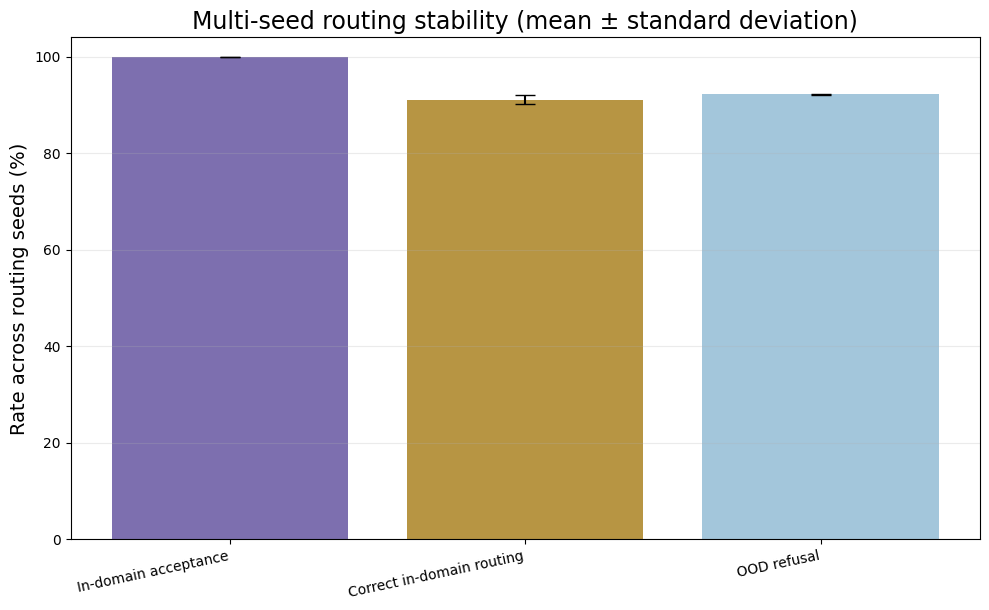

In [18]:
ROUTING_SEEDS = tuple(
    int(seed)
    for seed in globals().get("ROUTING_SEEDS", (0, 1, 2, 3, 4))
)
if len(set(ROUTING_SEEDS)) < 2:
    raise ValueError("ROUTING_SEEDS must contain at least two distinct seeds.")

ROUTING_CI_Z = 1.96


def route_with_exported_centroids(
        X_layer: np.ndarray,
        routing_centroids_local: Dict[int, torch.Tensor],
        trained_task_ids_local: List[int],
        layer_id: int,
        batch_size: int,
) -> pd.DataFrame:
    X_layer = np.asarray(X_layer, dtype=np.float32)
    if X_layer.ndim != 2:
        raise ValueError(f"Expected X_layer with shape [N, H], found {X_layer.shape}.")

    pc = routing_centroids_local[int(layer_id)]
    if not torch.is_tensor(pc):
        pc = torch.tensor(pc, dtype=torch.float32)
    pc = pc.detach().to(torch.float32).contiguous()

    task_ids_local = [int(task_id) for task_id in trained_task_ids_local]
    if pc.ndim != 2 or pc.shape[0] != len(task_ids_local):
        raise RuntimeError(
            "Routing-centroid rows and trained task IDs are inconsistent: "
            f"centroids={tuple(pc.shape)}, task_ids={len(task_ids_local)}."
        )

    pc_norms = torch.linalg.norm(pc, dim=-1)
    if torch.any(pc_norms <= 1e-12):
        raise RuntimeError("A routing centroid has zero norm.")
    pc_n = torch.nn.functional.normalize(pc, dim=-1, eps=1e-12)

    pred_task_ids = []
    routing_similarities = []
    for start in range(0, len(X_layer), int(batch_size)):
        xb = torch.as_tensor(
            X_layer[start:start + int(batch_size)],
            dtype=torch.float32,
        )
        xb_norms = torch.linalg.norm(xb, dim=-1)
        if torch.any(xb_norms <= 1e-12):
            raise RuntimeError(
                f"A prompt vector has zero norm in the batch starting at row {start}."
            )

        xb_n = torch.nn.functional.normalize(xb, dim=-1, eps=1e-12)
        similarities = xb_n @ pc_n.transpose(0, 1)
        routing_similarity, routing_idx = similarities.max(dim=-1)

        pred_task_ids.extend(
            task_ids_local[int(idx)]
            for idx in routing_idx.detach().cpu().tolist()
        )
        routing_similarities.extend(
            routing_similarity.detach().cpu().numpy().astype(np.float32).tolist()
        )

    return pd.DataFrame({
        "pred_task_id": np.asarray(pred_task_ids, dtype=int),
        "routing_similarity": np.asarray(routing_similarities, dtype=np.float32),
    })


def routing_metrics_at_threshold(
        in_domain_df: pd.DataFrame,
        in_domain_pred: pd.DataFrame,
        ood_pred: pd.DataFrame,
        threshold: float,
) -> Dict[str, float]:
    if len(in_domain_df) != len(in_domain_pred):
        raise RuntimeError(
            "In-domain data and predictions have different row counts: "
            f"{len(in_domain_df)} vs {len(in_domain_pred)}."
        )

    in_selected = (
        in_domain_pred["routing_similarity"].to_numpy(dtype=np.float32)
        >= float(threshold)
    )
    ood_selected = (
        ood_pred["routing_similarity"].to_numpy(dtype=np.float32)
        >= float(threshold)
    )
    correct = (
        in_selected
        & (
            in_domain_pred["pred_task_id"].to_numpy(dtype=int)
            == in_domain_df["task_id"].to_numpy(dtype=int)
        )
    )

    in_total = max(len(in_domain_df), 1)
    in_selected_count = int(in_selected.sum())
    ood_total = max(len(ood_pred), 1)

    global_correct_pct = 100.0 * float(correct.sum()) / in_total
    ood_refusal_pct = 100.0 * float((~ood_selected).sum()) / ood_total

    return {
        "rho": float(threshold),
        "in_domain_acceptance_pct": 100.0 * float(in_selected.sum()) / in_total,
        "in_domain_correct_routing_pct": global_correct_pct,
        "in_domain_selected_accuracy_pct": (
            100.0 * float(correct.sum()) / max(in_selected_count, 1)
        ),
        "ood_refusal_pct": ood_refusal_pct,
        "balanced_score_pct": min(global_correct_pct, ood_refusal_pct),
    }


def select_validation_rho(
        in_domain_df: pd.DataFrame,
        in_domain_pred: pd.DataFrame,
        ood_pred: pd.DataFrame,
) -> Tuple[float, pd.DataFrame]:
    sweep_df = pd.DataFrame([
        routing_metrics_at_threshold(
            in_domain_df=in_domain_df,
            in_domain_pred=in_domain_pred,
            ood_pred=ood_pred,
            threshold=rho,
        )
        for rho in REJECTION_ALPHAS
    ])

    best_row = (
        sweep_df
        .sort_values(
            by=[
                "balanced_score_pct",
                "in_domain_correct_routing_pct",
                "ood_refusal_pct",
                "rho",
            ],
            ascending=[False, False, False, True],
        )
        .iloc[0]
    )
    return float(best_row["rho"]), sweep_df


def summarize_seed_variance(
        df: pd.DataFrame,
        metrics: List[str],
        group_name: Optional[str] = None,
) -> pd.DataFrame:
    rows = []
    grouped = [(None, df)] if group_name is None else df.groupby(group_name, sort=True)

    for group_value, group_df in grouped:
        for metric in metrics:
            values = group_df[metric].astype(float).to_numpy()
            n = int(len(values))
            mean = float(np.mean(values))
            std = float(np.std(values, ddof=1)) if n > 1 else np.nan
            variance = float(np.var(values, ddof=1)) if n > 1 else np.nan
            ci_half_width = (
                ROUTING_CI_Z * std / math.sqrt(n)
                if n > 1 and np.isfinite(std)
                else np.nan
            )

            row = {
                "metric": metric,
                "n_seeds": n,
                "mean": mean,
                "std": std,
                "variance": variance,
                "min": float(np.min(values)),
                "max": float(np.max(values)),
                "ci95_low": mean - ci_half_width,
                "ci95_high": mean + ci_half_width,
            }
            if group_name is not None:
                row[group_name] = group_value
            rows.append(row)

    columns = ([group_name] if group_name is not None else []) + [
        "metric", "n_seeds", "mean", "std", "variance",
        "min", "max", "ci95_low", "ci95_high",
    ]
    return pd.DataFrame(rows)[columns]


validation_id_base = in_domain_eval_df[["task_id", "task_name"]].reset_index(drop=True)
test_id_base = test_in_domain_df[["task_id", "task_name"]].reset_index(drop=True)

routing_seed_rows = []
routing_per_task_seed_rows = []
routing_validation_sweeps = []

for routing_seed in ROUTING_SEEDS:
    seed_everything(int(routing_seed), deterministic_torch=True)

    seed_train_df = build_task_dataset_teacher_forcing_df(
        samples_per_task=ATAS_TRAIN_PER_TASK,
        seed=int(routing_seed),
        split="train",
    )

    seed_rng = np.random.default_rng(int(routing_seed))
    seed_alpha = {
        task_id: float(value)
        for task_id, value in zip(
            _task_ids_order,
            seed_rng.uniform(0.05, 1.0, size=len(_task_ids_order)),
        )
    }

    seed_executor = Executor(
        model=model,
        tokenizer=tokenizer,
        train_df=seed_train_df,
        mediator_type=MediatorTypeEnum.ATAS_CMD,
        layers_to_extract=[int(ATAS_LAYER)],
        atas_master_layer=int(ATAS_LAYER),
        batch_size=int(ATAS_EVAL_BATCH_SIZE),
        padding_side=tokenizer.padding_side,
        truncation_side=getattr(tokenizer, "truncation_side", "left"),
        dtype=getattr(model, "dtype", torch.float32),
        alpha=seed_alpha,
        generation_kwargs={},
        atas_similarity_threshold=0.0,
        tokens_window=-1,
        task_type=TaskTypeEnum.UNSUPERVISED,
        apply_from_token=-1,
        apply_from_mode=ApplyFromModeEnum.PROMPT_END,
        atas_use_last_token_for_prompt=True,
        use_last_token_for_response=True,
        decode_chunk_max=1,
        free_training_artifacts_after_build=True,
    )
    _ = seed_executor.representation_extractor()

    seed_strategy = seed_executor.steering_strategy
    if not isinstance(seed_strategy, AtasSteeringStrategy):
        raise RuntimeError(
            f"Expected AtasSteeringStrategy, found {type(seed_strategy).__name__}."
        )

    seed_routing_centroids, _, seed_task_ids = seed_strategy.export_params()
    seed_task_ids = [int(task_id) for task_id in seed_task_ids]

    validation_id_pred = route_with_exported_centroids(
        X_layer=X_in_domain_eval,
        routing_centroids_local=seed_routing_centroids,
        trained_task_ids_local=seed_task_ids,
        layer_id=ATAS_LAYER,
        batch_size=ATAS_EVAL_BATCH_SIZE,
    )
    validation_ood_pred = route_with_exported_centroids(
        X_layer=X_ood_eval,
        routing_centroids_local=seed_routing_centroids,
        trained_task_ids_local=seed_task_ids,
        layer_id=ATAS_LAYER,
        batch_size=ATAS_EVAL_BATCH_SIZE,
    )

    selected_rho, seed_sweep_df = select_validation_rho(
        in_domain_df=validation_id_base,
        in_domain_pred=validation_id_pred,
        ood_pred=validation_ood_pred,
    )
    seed_sweep_df.insert(0, "seed", int(routing_seed))
    routing_validation_sweeps.append(seed_sweep_df)

    validation_best = routing_metrics_at_threshold(
        in_domain_df=validation_id_base,
        in_domain_pred=validation_id_pred,
        ood_pred=validation_ood_pred,
        threshold=selected_rho,
    )

    test_id_pred = route_with_exported_centroids(
        X_layer=X_in_domain_test,
        routing_centroids_local=seed_routing_centroids,
        trained_task_ids_local=seed_task_ids,
        layer_id=ATAS_LAYER,
        batch_size=ATAS_EVAL_BATCH_SIZE,
    )
    test_ood_pred = route_with_exported_centroids(
        X_layer=X_ood_test,
        routing_centroids_local=seed_routing_centroids,
        trained_task_ids_local=seed_task_ids,
        layer_id=ATAS_LAYER,
        batch_size=ATAS_EVAL_BATCH_SIZE,
    )
    test_metrics = routing_metrics_at_threshold(
        in_domain_df=test_id_base,
        in_domain_pred=test_id_pred,
        ood_pred=test_ood_pred,
        threshold=selected_rho,
    )

    routing_seed_rows.append({
        "seed": int(routing_seed),
        "rho": selected_rho,
        "validation_balanced_score_pct": validation_best["balanced_score_pct"],
        "test_in_domain_acceptance_pct": test_metrics["in_domain_acceptance_pct"],
        "test_in_domain_correct_routing_pct": test_metrics["in_domain_correct_routing_pct"],
        "test_in_domain_selected_accuracy_pct": test_metrics["in_domain_selected_accuracy_pct"],
        "test_ood_refusal_pct": test_metrics["ood_refusal_pct"],
        "test_balanced_score_pct": test_metrics["balanced_score_pct"],
    })

    test_task_eval = test_id_base.copy()
    test_task_eval["selected"] = (
        test_id_pred["routing_similarity"].to_numpy(dtype=np.float32)
        >= selected_rho
    )
    test_task_eval["correct_routing"] = (
        test_task_eval["selected"].to_numpy(dtype=bool)
        & (
            test_id_pred["pred_task_id"].to_numpy(dtype=int)
            == test_task_eval["task_id"].to_numpy(dtype=int)
        )
    )

    for task_name, task_df in test_task_eval.groupby("task_name", sort=True):
        selected_count = int(task_df["selected"].sum())
        correct_count = int(task_df["correct_routing"].sum())
        routing_per_task_seed_rows.append({
            "seed": int(routing_seed),
            "rho": selected_rho,
            "task_name": task_name,
            "n_test": int(len(task_df)),
            "acceptance_pct": 100.0 * float(task_df["selected"].mean()),
            "correct_routing_pct": 100.0 * float(task_df["correct_routing"].mean()),
            "selected_accuracy_pct": 100.0 * correct_count / max(selected_count, 1),
        })

    del seed_executor, seed_strategy, seed_routing_centroids, seed_train_df
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


routing_multiseed_df = (
    pd.DataFrame(routing_seed_rows)
    .sort_values("seed")
    .reset_index(drop=True)
)
routing_validation_sweep_df = pd.concat(
    routing_validation_sweeps,
    ignore_index=True,
)
routing_per_task_multiseed_df = (
    pd.DataFrame(routing_per_task_seed_rows)
    .sort_values(["task_name", "seed"])
    .reset_index(drop=True)
)

routing_variance_summary_df = summarize_seed_variance(
    routing_multiseed_df,
    metrics=[
        "rho",
        "validation_balanced_score_pct",
        "test_in_domain_acceptance_pct",
        "test_in_domain_correct_routing_pct",
        "test_in_domain_selected_accuracy_pct",
        "test_ood_refusal_pct",
        "test_balanced_score_pct",
    ],
)

routing_per_task_variance_df = summarize_seed_variance(
    routing_per_task_multiseed_df,
    metrics=[
        "acceptance_pct",
        "correct_routing_pct",
        "selected_accuracy_pct",
    ],
    group_name="task_name",
)

print(f"Completed routing robustness analysis for {len(ROUTING_SEEDS)} seeds.")
display(routing_multiseed_df.round(4))
display(routing_variance_summary_df.round(6))
display(routing_per_task_variance_df.round(6))

plot_metrics = [
    "test_in_domain_acceptance_pct",
    "test_in_domain_correct_routing_pct",
    "test_ood_refusal_pct",
]
plot_labels = [
    "In-domain acceptance",
    "Correct in-domain routing",
    "OOD refusal",
]
plot_summary = routing_variance_summary_df.set_index("metric").loc[plot_metrics]

fig, ax = plt.subplots(figsize=(10, 6.2))
x_positions = np.arange(len(plot_metrics))
ax.bar(
    x_positions,
    plot_summary["mean"].to_numpy(dtype=float),
    yerr=plot_summary["std"].to_numpy(dtype=float),
    capsize=7,
    color=COLORS[:len(plot_metrics)],
    alpha=0.9,
)
ax.set_xticks(x_positions, plot_labels, rotation=12, ha="right")
ax.set_ylabel("Rate across routing seeds (%)", fontsize=14)
ax.set_title("Multi-seed routing stability (mean ± standard deviation)", fontsize=17)
ax.set_ylim(0, 104)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()

safe_model_name = "".join(
    char if char.isalnum() else "_"
    for char in MODEL_NAME.lower()
).strip("_")
os.makedirs("plots", exist_ok=True)
fig.savefig(
    os.path.join("plots", f"{safe_model_name}_routing_multiseed_variance.png"),
    dpi=300,
    bbox_inches="tight",
)
plt.show()
